# Viral Subtype Classification v2 — Fingerprint-Enriched Corpus + User-Labeled Partials → 10 Unlabeled Genomes

**Goal.** Train supervised classifiers on a **labeled reference corpus (4 subtypes: Ia, Ib1, Ib2, Ic)** enriched with a **FINGERPRINT SCORE** (unique sub-lineage identifiers carried per subtype / total possible identifiers for that subtype's identification), then assign the remaining **unlabeled partial DNA sequences** to their most likely subtype with **calibrated per-subtype probabilities**. The **SVM is the primary model**; every model is reported in an **identical format** (best params → CV metrics → held-out classification report → confusion-matrix figure → probability table for the new partials). The notebook ends with a written summary.

**What is new in v2 (preprocessing before modeling, per user instruction).**
1. **STEP 2a — k-mer conversion of ALL sequences BEFORE any modeling**: every sequence (references, all 32 partials) is explicitly converted into overlapping k-mer token counts over a fixed ACGT^k vocabulary and exported (`preprocessed_kmer_dataset.csv`); the modeling pipelines consume exactly this representation (consistency asserted in Step 4b).
2. **STEP 2b — user-label integration**: 22 of the 32 partials are user-labeled (21 × Ia + 1 × Ic, sequence 5 = Ic) and JOIN the training corpus with provenance tracking; the remaining 10 (12, 19, 20, 21, 23, 24, 25, 26, 31, 32) are the final classification targets.
3. **STEP 2c — class balancing, "pick the highest value" rule**: the highest per-subtype count in the training corpus is selected and EVERY subtype is brought UP to that count by random oversampling with replacement (disclosed in `balancing_report.csv`). The implementation is **fold-safe**: synthetic copies live only inside training folds, never in validation folds, so cross-validated metrics are not inflated by duplicated sequences.

**Biology in one paragraph.** The four subtypes present here (`Ia`, `Ib1`, `Ib2`, `Ic`) are close sub-lineages of a short viral amplicon (~250 nt). At this evolutionary distance, subtype identity is carried by a small number of single-nucleotide substitutions (SNPs) rather than by gross composition differences, so the feature space is built from **normalized k-mer frequencies** (which tolerate partial genomes and the 1-nt length offset between references and the 32 partials), **cosine similarities to subtype k-mer centroids / nearest references**, **GC content**, and a **CpG observed/expected ratio**. On top of the raw sequence evidence, the corpus carries laboratory **fingerprint scores** — the fraction of known sub-lineage identifier markers a genome carries for *its own* subtype — which we use exactly as the analysis protocol prescribes (label-noise QC, EDA, sensitivity analysis) and which we *mimic* at inference time by **mining subtype-diagnostic k-mer markers** from the references themselves to build a *digital fingerprint profile* for every sequence, including the 32.

**Anti-leakage contract (enforced in code).**
1. The **10 remaining unlabeled** partials **never** touch training, scaling, feature fitting, calibration, or tuning — they are only ever `transform`-ed / `predict`-ed. The 22 user-labeled partials join the training corpus in Step 2b (with provenance tracking); synthetic balancing copies exist only inside training folds.
2. All feature machinery lives inside sklearn `Pipeline`s, so per CV fold the transformers (subtype centroids, anchor references, mined markers) are re-fit **on the training folds only**.
3. The Schema-B self-score is **label-dependent** and therefore **forbidden as a model feature**; no raw length, sequence ID, or header text is used either.
4. No fingerprint scores are ever fabricated for the 32 — only mined-marker profiles with a disclosed method and validation statistics.

**Determinism.** `random_state = 42` everywhere; splits, CV folds, bootstrap resampling and permutation importance are seeded; grid search, CV, and all estimators run with `n_jobs=1` for full reproducibility.

**Deliverables produced by this notebook.** Figures `fig1`–`fig13` (`.png`, dpi 300, saved *before* `plt.show()`), and CSVs: `new_sequence_predictions.csv`, `model_comparison.csv`, `per_model_confusion_matrices.csv`, `mined_markers.csv`, `flagged_references.csv`, `permutation_importance.csv`, `fingerprint_scores_for_new32.csv` (plus a convenience wide-format final-model table, the feature-set comparison table, and the two NEW preprocessing artifacts `preprocessed_kmer_dataset.csv` + `balancing_report.csv`).


In [ ]:
import os

FILES = {
    'references_csv': 'reference_sequences.csv',
    'new_sequences':  'sequences.csv',
}

COLUMN_MAP = {'id': None, 'sequence': None, 'label': None, 'fingerprint': None}

SEARCH_DIRS = ['.', 'input', 'data', 'upload']
OUTDIR = '.'

RANDOM_STATE      = 42
TEST_SIZE         = 0.20
FP_FLAG_THRESHOLD = 0.5
NEARDUP_K         = 8
NEARDUP_J         = 0.99

USER_LABELED_SEQ_NUMS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17, 18, 22, 27, 28, 29, 30]
USER_LABELED_LABELS   = ['Ia', 'Ia', 'Ia', 'Ia', 'Ic', 'Ia', 'Ia', 'Ia', 'Ia', 'Ia',
                         'Ia', 'Ia', 'Ia', 'Ia', 'Ia', 'Ia', 'Ia', 'Ia', 'Ia', 'Ia', 'Ia', 'Ia']
USER_LABEL_MAP = dict(zip(USER_LABELED_SEQ_NUMS, USER_LABELED_LABELS))
BALANCE_RULE   = 'oversample_to_max'

KMER_K_CANDIDATES = [3, 4, 5]
KMER_K_DEFAULT    = 4

MARKER_K_GRID     = [4, 5, 6, 7, 8]
MARKER_X_GRID     = [0.6, 0.8, 1.0]
MARKER_Y_GRID     = [0.1, 0.2, 0.3]
MARKER_CAP        = 60
FP_VALID_R_MIN    = 0.6
FP_VALID_MIN_NSUB = 2

LOW_CONF_MAXP, LOW_CONF_MARGIN, LOW_CONF_ENTROPY = 0.6, 0.15, 0.9

N_BOOT            = 1000
N_PERM_REPEATS    = 50
DPI               = 300

from IPython.display import display


In [ ]:
%matplotlib inline

import sys, time, re, warnings
from collections import Counter, defaultdict
from itertools import product

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt

try:
    import seaborn as sns
    HAS_SNS = True
except Exception:
    HAS_SNS = False

import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.model_selection import (train_test_split, StratifiedKFold, LeaveOneOut,
                                     GridSearchCV, cross_val_predict, cross_validate)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, confusion_matrix, roc_auc_score, roc_curve)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, VotingClassifier, StackingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from scipy.stats import spearmanr

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except Exception:
    HAS_LGBM = False
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except Exception:
    HAS_XGB = False
try:
    import Bio
    HAS_BIO = True
except Exception:
    HAS_BIO = False

warnings.filterwarnings('ignore', category=FutureWarning)
try:
    from sklearn.exceptions import ConvergenceWarning
    warnings.filterwarnings('ignore', category=ConvergenceWarning)
except Exception:
    pass
warnings.filterwarnings('ignore', message='.*does not have valid feature names.*')
warnings.filterwarnings('ignore', message='.*X has feature names.*')

np.random.seed(RANDOM_STATE)
import random; random.seed(RANDOM_STATE)

if HAS_SNS:
    sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = DPI
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)

def save_and_show(fname, fig=None):
    fig = fig if fig is not None else plt.gcf()
    fig.savefig(os.path.join(OUTDIR, fname), dpi=DPI)
    plt.show()
    plt.close(fig)

## STEP 1 — Loading, Schema Detection & Quality Control

**What happens here and why.** The reference corpus is loaded with a *defensive* column-detection routine: the sequence column is identified as the column holding the longest A/C/G/T/N strings, the label column by name/low-cardinality heuristics, and the fingerprint column(s) by name plus a value-shape test that understands both plain numeric scores and `count/total` ratio strings. The loader then decides between the two supported schemas and **prints the branch taken**:

- **SCHEMA A (profile)** — one fingerprint score *per subtype* (`Fingerprint_Subtype1..4`): scores become (i) model features in a Hybrid set, (ii) a standalone Fingerprint Baseline classifier, and (iii) inputs to marker mining.
- **SCHEMA B (single)** — one score = identifier fraction for the sequence's **own** labeled subtype. Because the value depends on the label, it is **label-dependent and forbidden as a feature**. It is used only for (a) label-noise QC (references scoring low for their own subtype are flagged as possible mislabels → `flagged_references.csv`), (b) EDA by subtype (fig2), and (c) a sensitivity analysis that re-runs the best model with flagged references removed vs retained.

If schema detection fails, the cell prints the detected columns and a sample row and **stops** (per protocol), rather than guessing. Sequences are upper-cased; ambiguous IUPAC codes are counted (they are excluded from k-mer counting but disclosed), per-subtype counts and length statistics are tabulated against the 32 partials, and fig1 visualizes class balance and length distributions.


In [ ]:
BASES = 'ACGT'

def _resolve_path(fname):
    for d in SEARCH_DIRS:
        p = os.path.join(d, fname) if d else fname
        if os.path.isfile(p):
            return p
    raise FileNotFoundError(f'Could not find "{fname}" in any of: {SEARCH_DIRS}')

def _is_seqlike(v, min_len=30):
    if not isinstance(v, str):
        return False
    s = v.strip().upper()
    return len(s) >= min_len and set(s) <= set('ACGTN')

def _column_seqness(df, col):
    vals = df[col].dropna().astype(str)
    if len(vals) == 0:
        return 0.0
    frac = 0.0
    for v in vals.head(200):
        s = v.strip().upper()
        if len(s) == 0:
            continue
        frac += sum(1 for ch in s if ch in 'ACGTN') / len(s)
    return frac / max(1, min(len(vals), 200))

def _read_table_autodetect(path):
    raw = pd.read_csv(path, header=None, dtype=str)
    first_row = raw.iloc[0].astype(str).tolist()
    if any(_is_seqlike(v, min_len=50) for v in first_row):
        return raw, True
    return pd.read_csv(path, header=0, dtype=str), False

def load_fasta(path):
    recs, name, buf = [], None, []
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if line.startswith('>'):
                if name is not None:
                    recs.append((name, ''.join(buf)))
                name, buf = line[1:].split()[0] if line[1:] else f'seq{len(recs)+1}', []
            elif line:
                buf.append(line)
    if name is not None:
        recs.append((name, ''.join(buf)))
    return pd.DataFrame(recs, columns=['id', 'sequence'])

def detect_columns(df, source):
    log, cols = [], list(df.columns)

    seq_scores = {c: _column_seqness(df, c) for c in cols}
    seq_cols = [c for c in cols if seq_scores[c] > 0.9]
    if not seq_cols:
        seq_cols = [c for c in cols if seq_scores[c] > 0.5]
    seq_col = max(seq_cols, key=lambda c: df[c].dropna().astype(str).str.len().max()) if seq_cols else None
    log.append(f'sequence column candidates (seqness>0.5): {seq_cols} -> chose "{seq_col}"')
    nonseq = [c for c in cols if c != seq_col]

    label_col = None
    for c in nonseq:
        if re.search(r'subtype|label|class|lineage|type', str(c), flags=re.I):
            label_col = c
            break
    if label_col is None:
        for c in nonseq:
            nun = df[c].dropna().nunique()
            if 2 <= nun <= 12:
                label_col = c
                break
    log.append(f'label column -> "{label_col}"')

    fp_cols, fp_kind = [], None
    for c in nonseq:
        if c == label_col:
            continue
        cname = str(c).lower()
        if re.search(r'fingerprint|identif|marker|(^|_)fp(_|$)', cname):
            sample = df[c].dropna().astype(str).head(50)
            ratio = sample.str.match(r'^\s*\d+\s*/\s*\d+\s*$').mean()
            numeric = pd.to_numeric(sample, errors='coerce').notna().mean()
            if ratio > 0.5:
                fp_cols.append(c); fp_kind = 'ratio'
            elif numeric > 0.5:
                fp_cols.append(c); fp_kind = fp_kind or 'numeric'
    log.append(f'fingerprint columns (name+shape test) -> {fp_cols} (value kind: {fp_kind})')

    id_col = None
    for c in nonseq:
        if c in (label_col,):
            continue
        if re.search(r'(^|_)id$|seq_id|^name$|^no$|^num|^index', str(c), flags=re.I):
            id_col = c
            break
    if id_col is None:
        cands = [c for c in nonseq if c not in (label_col,) + tuple(fp_cols)]
        if cands:
            id_col = cands[0]
    log.append(f'id column -> "{id_col}"')
    return {'sequence': seq_col, 'label': label_col, 'fingerprint': fp_cols, 'id': id_col,
            'fp_kind': fp_kind, 'log': log}

def parse_fp_value(v):
    s = str(v).strip()
    m = re.match(r'^(\d+)\s*/\s*(\d+)$', s)
    if m:
        n_, d_ = int(m.group(1)), int(m.group(2))
        return n_, d_, (n_ / d_ if d_ else np.nan)
    try:
        f = float(s)
        return np.nan, np.nan, f
    except Exception:
        return np.nan, np.nan, np.nan

def load_data():
    ref_path = _resolve_path(FILES['references_csv'])
    ref_df, headerless = _read_table_autodetect(ref_path)
    det = detect_columns(ref_df, 'references')
    if COLUMN_MAP['sequence']:
        det['sequence'] = COLUMN_MAP['sequence']
    if COLUMN_MAP['label']:
        det['label'] = COLUMN_MAP['label']
    if COLUMN_MAP['fingerprint']:
        det['fingerprint'] = [COLUMN_MAP['fingerprint']]
    ok = det['sequence'] is not None and det['label'] is not None and len(det['fingerprint']) >= 1
    if not ok:
        raise RuntimeError('Schema detection failed for the reference corpus.')
    ref = pd.DataFrame({
        'ref_id': [f'ref_{i+1:03d}' for i in range(len(ref_df))],
        'sequence': ref_df[det['sequence']].astype(str).str.upper().str.strip(),
        'subtype': ref_df[det['label']].astype(str).str.strip(),
    })
    fps = det['fingerprint']
    if len(fps) == 1:
        parsed = ref_df[fps[0]].apply(parse_fp_value)
        ref['fp_num'] = [p[0] for p in parsed]
        ref['fp_den'] = [p[1] for p in parsed]
        ref['fp_frac'] = [p[2] for p in parsed]
        ref['fp_source_col'] = fps[0]
        schema = 'B'
    else:

        schema = 'A'
        for c in fps:
            parsed = ref_df[c].apply(parse_fp_value)
            ref[f'fp_num_{c}'] = [p[0] for p in parsed]
            ref[f'fp_frac_{c}'] = [p[2] for p in parsed]
        ref['fp_source_cols'] = ';'.join(map(str, fps))

    new_path = _resolve_path(FILES['new_sequences'])
    if new_path.lower().endswith(('.fasta', '.fa', '.fna', '.ffn')) or open(new_path).read(1) == '>':
        new_df = load_fasta(new_path).rename(columns={'id': 'new_id'})
    else:
        ndf, headerless_new = _read_table_autodetect(new_path)
        ndet = detect_columns(ndf, 'new_sequences')
        if COLUMN_MAP['sequence']:
            ndet['sequence'] = COLUMN_MAP['sequence']
        if ndet['sequence'] is None:
            raise RuntimeError('Schema detection failed for the new sequences.')
        nid = ndet['id'] if ndet['id'] is not None else None
        new_df = pd.DataFrame({
            'new_id': ndf[nid].astype(str).str.strip() if nid is not None else [f'new_{i+1:03d}' for i in range(len(ndf))],
            'sequence': ndf[ndet['sequence']].astype(str).str.upper().str.strip(),
        })
    return ref, new_df, schema, det

REF_DF, NEW_DF, SCHEMA, REF_DET = load_data()

display(REF_DF.head(2))
display(NEW_DF.head(2))

,ref_id,sequence,subtype,fp_num,fp_den,fp_frac,fp_source_col
0,ref_001,GTAGATGCTATTACAGAGGTAGAATGCTTCCTAAACCCAGAAATGG...,Ia,3,12,0.250000,unique_subtype_fingerprints_count_out_of_total
1,ref_002,GTAGATGCTATAACAGAGGTAGAATGCTTCCTAAACCCAGAAATGG...,Ib1,2,3,0.666667,unique_subtype_fingerprints_count_out_of_total


,new_id,sequence
0,1,GGTAGATGCTATTACAGAGGTAGAATGCTTCCTAAACCCAGAAATG...
1,2,GGTAGATGCTATTACAGAGGTAGAATGCTTCCTAAACCCAGAAATG...


In [4]:
def ambiguous_counts(seq):
    return Counter(ch for ch in seq if ch not in 'ACGT')

REF_DF['n_ambiguous'] = REF_DF['sequence'].apply(lambda s: sum(ambiguous_counts(s).values()))
NEW_DF['n_ambiguous'] = NEW_DF['sequence'].apply(lambda s: sum(ambiguous_counts(s).values()))
REF_DF['length'] = REF_DF['sequence'].str.len()
NEW_DF['length'] = NEW_DF['sequence'].str.len()

amb_ref = Counter()
for s in REF_DF['sequence']:
    amb_ref.update(ambiguous_counts(s))
amb_new = Counter()
for s in NEW_DF['sequence']:
    amb_new.update(ambiguous_counts(s))
if amb_ref:
    rows_with_amb = REF_DF[REF_DF['n_ambiguous'] > 0][['ref_id', 'subtype', 'n_ambiguous', 'fp_num', 'fp_den', 'fp_frac']]
    display(rows_with_amb)

sub_stats = REF_DF.groupby('subtype').agg(
    n_refs=('sequence', 'size'),
    len_min=('length', 'min'), len_median=('length', 'median'), len_max=('length', 'max'),
    fp_min=('fp_frac', 'min'), fp_median=('fp_frac', 'median'), fp_max=('fp_frac', 'max'),
)
display(sub_stats)

,ref_id,subtype,n_ambiguous,fp_num,fp_den,fp_frac
47,ref_048,Ia,1,1,12,0.083333


,n_refs,len_min,len_median,len_max,fp_min,fp_median,fp_max
subtype,,,,,,,
Ia,14,249,249.0,249,0.083333,0.333333,0.583333
Ib1,22,249,249.0,249,0.666667,0.666667,1.000000
Ib2,34,249,249.0,249,0.285714,0.571429,0.857143
Ic,18,249,249.0,249,0.250000,0.291667,0.416667


In [ ]:
if SCHEMA != 'B':
    FLAGGED_DF = pd.DataFrame(columns=['ref_id', 'subtype', 'fp_num', 'fp_den', 'fp_frac', 'reasons'])
else:

    low_mask = REF_DF['fp_frac'] < FP_FLAG_THRESHOLD

    lab_per_seq = REF_DF.groupby('sequence')['subtype'].nunique()
    conflict_seqs = set(lab_per_seq[lab_per_seq > 1].index)
    conflict_mask = REF_DF['sequence'].isin(conflict_seqs)

    reasons = []
    for i, row in REF_DF.iterrows():
        r = []
        if low_mask.loc[i]:
            r.append(f'low self-score < {FP_FLAG_THRESHOLD}')
        if conflict_mask.loc[i]:
            others = sorted(set(REF_DF.loc[REF_DF['sequence'] == row['sequence'], 'subtype']) - {row['subtype']})
            r.append(f'sequence-identical row(s) labeled {",".join(others)}')
        reasons.append('; '.join(r))
    FLAGGED_DF = REF_DF.loc[[bool(r) for r in reasons], ['ref_id', 'subtype', 'fp_num', 'fp_den', 'fp_frac']].copy()
    FLAGGED_DF['reasons'] = [r for r in reasons if r]
    FLAGGED_DF.to_csv(os.path.join(OUTDIR, 'flagged_references.csv'), index=False)
    display(pd.DataFrame({'low_selfscore': low_mask.groupby(REF_DF['subtype']).sum(), 'label_conflict': conflict_mask.groupby(REF_DF['subtype']).sum()}))

[flagged_references.csv] written: 48 of 88 reference rows flagged (threshold: self-score < 0.5).


,low_selfscore,label_conflict
subtype,,
Ia,10,0
Ib1,0,19
Ib2,1,1
Ic,18,0


/tmp/ipykernel_1203/1087836311.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{st}\n(n={len(d)})' for st, d in zip(order, data)])


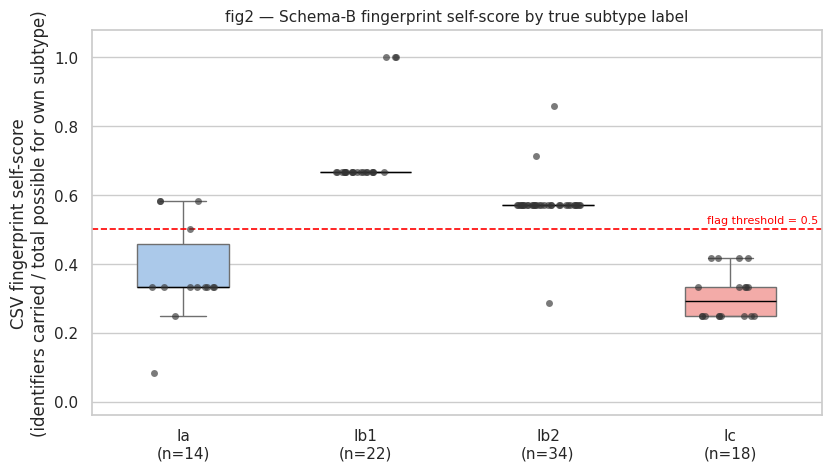

In [6]:
if SCHEMA == 'B':
    fig, ax = plt.subplots(figsize=(8.2, 4.6), constrained_layout=True)
    order = sorted(REF_DF['subtype'].unique())
    data = [REF_DF.loc[REF_DF['subtype'] == st, 'fp_frac'].values for st in order]
    if HAS_SNS:
        sns.boxplot(data=data, ax=ax, width=0.5, palette='pastel', showfliers=False,
                    medianprops=dict(color='black'))
        sns.stripplot(data=data, ax=ax, size=5, jitter=0.18, color='#333333', alpha=0.65)
    else:
        ax.boxplot(data, labels=order)
    ax.axhline(FP_FLAG_THRESHOLD, color='red', ls='--', lw=1.2)
    ax.text(0.995, FP_FLAG_THRESHOLD + 0.012, f'flag threshold = {FP_FLAG_THRESHOLD}', color='red',
            ha='right', va='bottom', fontsize=8, transform=ax.get_yaxis_transform())
    ax.set_xticklabels([f'{st}\n(n={len(d)})' for st, d in zip(order, data)])
    ax.set_ylabel('CSV fingerprint self-score\n(identifiers carried / total possible for own subtype)')
    ax.set_ylim(-0.04, 1.08)
    ax.set_title('fig2 — Schema-B fingerprint self-score by true subtype label', fontsize=11)
    save_and_show('fig2_fingerprint_eda.png', fig)

    med = {st: float(np.median(d)) for st, d in zip(order, data)}
    rng = {st: (float(np.min(d)), float(np.max(d))) for st, d in zip(order, data)}
    hi = [st for st in order if med[st] >= 0.6]
    lo = [st for st in order if med[st] < 0.6]

In [7]:
n_before = len(REF_DF)
DEDUP_DF = REF_DF.drop_duplicates(subset=['sequence', 'subtype'] +
                                  ([c for c in REF_DF.columns if c.startswith('fp_num_')] if SCHEMA == 'A'
                                   else ['fp_num', 'fp_den'])).reset_index(drop=True)
dd_tab = pd.DataFrame({'raw_rows': REF_DF['subtype'].value_counts().sort_index(),
                       'unique_rows': DEDUP_DF['subtype'].value_counts().sort_index()})
dd_tab['duplicates_removed'] = dd_tab['raw_rows'] - dd_tab['unique_rows']
display(dd_tab)

def kmer_set(seq, k):
    return {seq[i:i + k] for i in range(len(seq) - k + 1) if set(seq[i:i + k]) <= set('ACGT')}

ref_kmersets = [kmer_set(s, NEARDUP_K) for s in DEDUP_DF['sequence']]
rows = []
for i, s in enumerate(NEW_DF['sequence']):
    ks = kmer_set(s, NEARDUP_K)
    best_j, best_j_val = -1, -1.0
    for j, rk in enumerate(ref_kmersets):
        inter = len(ks & rk); union = len(ks | rk)
        jv = inter / union if union else 0.0
        if jv > best_j_val:
            best_j, best_j_val = j, jv
    rows.append({'new_id': NEW_DF['new_id'].iloc[i], f'jaccard_k{NEARDUP_K}': best_j_val,
                 'best_match_ref': DEDUP_DF['ref_id'].iloc[best_j],
                 'best_match_subtype': DEDUP_DF['subtype'].iloc[best_j],
                 'near_duplicate': best_j_val > NEARDUP_J})
NEARDUP_TABLE = pd.DataFrame(rows)
n_near = int(NEARDUP_TABLE['near_duplicate'].sum())
display(NEARDUP_TABLE.sort_values(f'jaccard_k{NEARDUP_K}', ascending=False).head(10))

,raw_rows,unique_rows,duplicates_removed
subtype,,,
Ia,14,6,8
Ib1,22,2,20
Ib2,34,4,30
Ic,18,7,11


,new_id,jaccard_k8,best_match_ref,best_match_subtype,near_duplicate
21,22,0.995833,ref_016,Ia,True
27,28,0.995833,ref_016,Ia,True
19,20,0.995833,ref_016,Ia,True
22,23,0.935223,ref_001,Ia,False
20,21,0.935223,ref_001,Ia,False
24,25,0.935223,ref_001,Ia,False
25,26,0.935223,ref_001,Ia,False
23,24,0.935223,ref_001,Ia,False
7,8,0.934959,ref_002,Ib1,False
15,16,0.934959,ref_002,Ib1,False


## STEP 2 (NEW) — Preprocessing BEFORE Modeling: k-mer Conversion, User-Label Integration & Class Balancing

Per the user instruction, three preprocessing stages now run **before any model is touched**, and every later step consumes their output:

1. **STEP 2a — k-mer conversion of ALL sequences.** Every sequence available at this point (the deduplicated references *and* all 32 partials from `sequences.csv`) is explicitly converted into **overlapping k-mer token counts** over a **fixed vocabulary = all ACGT^k strings** (k ∈ {3,4,5}; k-mers overlapping non-ACGT bases are skipped). Because the vocabulary is fixed by the alphabet rather than learned from the data, the conversion is a pure per-sequence transform — leakage-free by construction — and the result is materialized and exported as `preprocessed_kmer_dataset.csv`. The modeling pipelines in Steps 3–6 consume exactly this representation (an `np.allclose` consistency assertion in Step 4b proves it).
2. **STEP 2b — user-label integration.** The 22 user-labeled partials (21 × Ia + 1 × Ic; sequence 5 = Ic) are joined to the deduplicated references to form the **training corpus**, with a `provenance` column (`reference` vs `user_labeled`) so every downstream table can distinguish the two sources. Exact-duplicate handling runs inside this stage (identical strings cannot be allowed to appear on both sides of a CV fold), and any user-vs-reference label conflict on a sequence-identical pair would be disclosed loudly. The remaining 10 partials become the **final classification targets**.
3. **STEP 2c — class balancing ("pick the highest value").** The largest per-subtype count in the training corpus is selected, and **every subtype is brought UP to that count** by random oversampling with replacement (`random_state=42`) — no data is discarded, unlike downsampling. The implementation is **fold-safe**: the augmentation is re-derived on the *training split only* in Step 4, and **validation folds always contain original rows only**, so duplicated sequences can never inflate cross-validated metrics. The materialized balanced view built here is for reporting and fig1; `balancing_report.csv` records the exact per-subtype counts.
4. **STEP 2d — fig1**, now with a third panel showing the corpus composition after integration and balancing.

**Why fold-safe oversampling matters.** Naively duplicating minority rows *before* splitting would place copies of a sequence in both a training fold and its validation fold whenever the original is validated — the model would be graded on items it memorized. Re-deriving the augmentation per training fold (copies only where the parent is in-fold) keeps LOOCV/CV honest while still giving every subtype an equal *effective* training count, exactly as the "pick the highest value" rule requires.


In [ ]:
KMER_KS = sorted(set(KMER_K_CANDIDATES) | {KMER_K_DEFAULT})

def sequence_to_kmers(seq, k):
    return [seq[i:i + k] for i in range(len(seq) - k + 1) if not (set(seq[i:i + k]) - set(BASES))]

def kmer_freq_vector(seq, k, vocab):
    toks = sequence_to_kmers(seq, k)
    tot = len(toks)
    if tot == 0:
        return np.zeros(len(vocab), dtype=float)
    c = Counter(toks)
    return np.array([c.get(km, 0) / tot for km in vocab], dtype=float)

VOCABS = {k: [''.join(p) for p in product(BASES, repeat=k)] for k in KMER_KS}

PREP_ROWS = []
for _, r in DEDUP_DF.iterrows():
    PREP_ROWS.append((r['ref_id'], 'reference', r['sequence']))
for _, r in NEW_DF.iterrows():
    PREP_ROWS.append((f"n{int(r['new_id']):02d}", 'new32', r['sequence']))

KMER_FREQ = {}
stat_rows = []
for k in KMER_KS:
    toks_all = [sequence_to_kmers(s, k) for _, _, s in PREP_ROWS]
    for (uid, _grp, _s), toks in zip(PREP_ROWS, toks_all):
        KMER_FREQ.setdefault(uid, {})[k] = kmer_freq_vector(_s, k, VOCABS[k])
    n_tok = np.array([len(t) for t in toks_all], float)
    n_dis = np.array([len(set(t)) for t in toks_all], float)
    all_tokens = Counter(t for toks in toks_all for t in toks)
    top3 = ', '.join(f'{km} ({n})' for km, n in all_tokens.most_common(3))
    stat_rows.append({'k': k, 'fixed_vocab_size': len(VOCABS[k]), 'mean_tokens_per_seq': n_tok.mean(),
                      'mean_distinct_kmers_per_seq': n_dis.mean(), 'top3_kmers_overall': top3})
STAT_DF = pd.DataFrame(stat_rows)
display(STAT_DF.round(1))

prep_frames = []
for k in KMER_KS:
    M = np.vstack([KMER_FREQ[uid][k] for uid, _, _ in PREP_ROWS])
    prep_frames.append(pd.DataFrame(M, columns=[f'k{k}_{km}' for km in VOCABS[k]]))
PREP_DF = pd.concat(
    [pd.DataFrame({'seq_uid': [u for u, _, _ in PREP_ROWS],
                   'group': [g for _, g, _ in PREP_ROWS],
                   'length': [len(s) for _, _, s in PREP_ROWS]})] + prep_frames, axis=1)
PREP_DF.to_csv(os.path.join(OUTDIR, 'preprocessed_kmer_dataset.csv'), index=False)

,k,fixed_vocab_size,mean_tokens_per_seq,mean_distinct_kmers_per_seq,top3_kmers_overall
0,3,64,247.6,55.1,"AAA (694), AGA (471), AAT (459)"
1,4,256,246.5,135.1,"GAAA (283), CAGA (255), AATG (255)"
2,5,1024,245.5,199.6,"AAATG (196), ATGCT (153), CCAGA (152)"


[preprocessed_kmer_dataset.csv] written: 51 rows x 1347 columns (normalized k-mer frequencies on the FIXED vocabulary + uid/group/length).


In [9]:
assert len(USER_LABELED_SEQ_NUMS) == len(USER_LABELED_LABELS), 'config error: numbers/labels length mismatch'
NEW_NUMS = NEW_DF['new_id'].astype(int)
id2seq = dict(zip(NEW_NUMS, NEW_DF['sequence']))
missing = [n for n in USER_LABELED_SEQ_NUMS if n not in id2seq]
assert not missing, f'config error: sequence numbers not present in sequences.csv: {missing}'
VALID_SUBTYPES = sorted(DEDUP_DF['subtype'].unique())
bad_labels = sorted(set(USER_LABELED_LABELS) - set(VALID_SUBTYPES))
assert not bad_labels, f'config error: user labels {bad_labels} do not exist in the reference subtype set {VALID_SUBTYPES}'

rows = []
for n, lab in zip(USER_LABELED_SEQ_NUMS, USER_LABELED_LABELS):
    s = id2seq[n]
    rows.append({'corpus_id': f'u{n:02d}', 'seq_num': n, 'sequence': s, 'subtype': lab,
                 'provenance': 'user_labeled', 'fp_num': np.nan, 'fp_den': np.nan, 'fp_frac': np.nan,
                 'fp_source_col': np.nan,
                 'n_ambiguous': sum(1 for ch in s if ch not in BASES), 'length': len(s)})
USER_LAB_DF = pd.DataFrame(rows)

dup_mask = USER_LAB_DF.duplicated(subset=['sequence'], keep='first')
if dup_mask.any():
    dropped = USER_LAB_DF.loc[dup_mask, ['corpus_id', 'subtype']].to_dict('records')
    USER_LAB_DF = USER_LAB_DF.loc[~dup_mask].reset_index(drop=True)

ref_seq2lab = DEDUP_DF.groupby('sequence')['subtype'].apply(list).to_dict()
redundant_ids, conflicts = [], []
for _, r in USER_LAB_DF.iterrows():
    if r['sequence'] in ref_seq2lab:
        if r['subtype'] in ref_seq2lab[r['sequence']]:
            redundant_ids.append(r['corpus_id'])
        else:
            conflicts.append((r['corpus_id'], r['subtype'], ref_seq2lab[r['sequence']]))
if redundant_ids:
    USER_LAB_DF = USER_LAB_DF[~USER_LAB_DF['corpus_id'].isin(redundant_ids)].reset_index(drop=True)

TO_CLASSIFY_DF = NEW_DF[~NEW_NUMS.isin(USER_LABELED_SEQ_NUMS)].copy().reset_index(drop=True)
TO_CLASSIFY_DF['seq_id'] = TO_CLASSIFY_DF['new_id'].astype(str)

ref_part = DEDUP_DF.copy()
ref_part['corpus_id'] = ref_part['ref_id']
ref_part['provenance'] = 'reference'
CORPUS_COLS = ['corpus_id', 'sequence', 'subtype', 'provenance', 'fp_num', 'fp_den', 'fp_frac',
               'fp_source_col', 'n_ambiguous', 'length']
CORPUS_DF = pd.concat([ref_part[CORPUS_COLS], USER_LAB_DF[CORPUS_COLS]], ignore_index=True)
display(CORPUS_DF.groupby(['subtype', 'provenance']).size().unstack(fill_value=0))

provenance,reference,user_labeled
subtype,,
Ia,6,4
Ib1,2,0
Ib2,4,0
Ic,7,1


In [ ]:
def make_balanced_augment(X_df, y, seed=RANDOM_STATE):
    y = np.asarray(y)
    rng = np.random.default_rng(seed)
    counts = Counter(y.tolist())
    target = int(max(counts.values()))
    picks = []
    for c in sorted(counts):
        idx_c = np.where(y == c)[0]
        need = target - len(idx_c)
        if need > 0:
            picks.extend(int(p) for p in rng.choice(idx_c, size=need, replace=True))
    order = np.array(list(range(len(y))) + picks, dtype=int)
    return X_df.iloc[order].reset_index(drop=True), y[order], order.tolist(), len(y)

def splits_balanced(n_orig, copy_of, mode='loo', y_orig=None, n_splits=5, seed=RANDOM_STATE):
    copy_pos = np.arange(n_orig, len(copy_of))
    parent = np.asarray(copy_of[n_orig:])
    def _tr(tr_o):
        cp = copy_pos[np.isin(parent, tr_o)]
        return np.concatenate([np.asarray(tr_o, dtype=int), cp]).astype(int)
    out = []
    if mode == 'loo':
        for i in range(n_orig):
            tr_o = np.array([j for j in range(n_orig) if j != i], dtype=int)
            out.append((_tr(tr_o), np.array([i], dtype=int)))
    else:
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        for tr_o, te_o in skf.split(np.zeros((n_orig, 1)), np.asarray(y_orig)):
            out.append((_tr(tr_o), np.asarray(te_o, dtype=int)))
    return out

counts0 = CORPUS_DF['subtype'].value_counts().sort_index()
TARGET_N = int(counts0.max())
rng_bal = np.random.default_rng(RANDOM_STATE)
pick_pos_full = []
for c in sorted(counts0.index):
    idx_c = np.where(CORPUS_DF['subtype'].values == c)[0]
    need = TARGET_N - len(idx_c)
    if need > 0:
        pick_pos_full.extend(int(p) for p in rng_bal.choice(idx_c, size=need, replace=True))
BALANCE_REPORT = pd.DataFrame({
    'subtype': counts0.index,
    'original_rows': counts0.values.astype(int),
    'target_highest_value': TARGET_N,
    'copies_added': [int(TARGET_N - counts0[c]) for c in counts0.index],
})
BALANCE_REPORT.to_csv(os.path.join(OUTDIR, 'balancing_report.csv'), index=False)
display(BALANCE_REPORT)

[balancing_report.csv] written.  Balancing rule: pick the HIGHEST per-subtype count (= 10) and bring every subtype up to it by sampling WITH replacement.


,subtype,original_rows,target_highest_value,copies_added
0,Ia,10,10,0
1,Ib1,2,10,8
2,Ib2,4,10,6
3,Ic,8,10,2


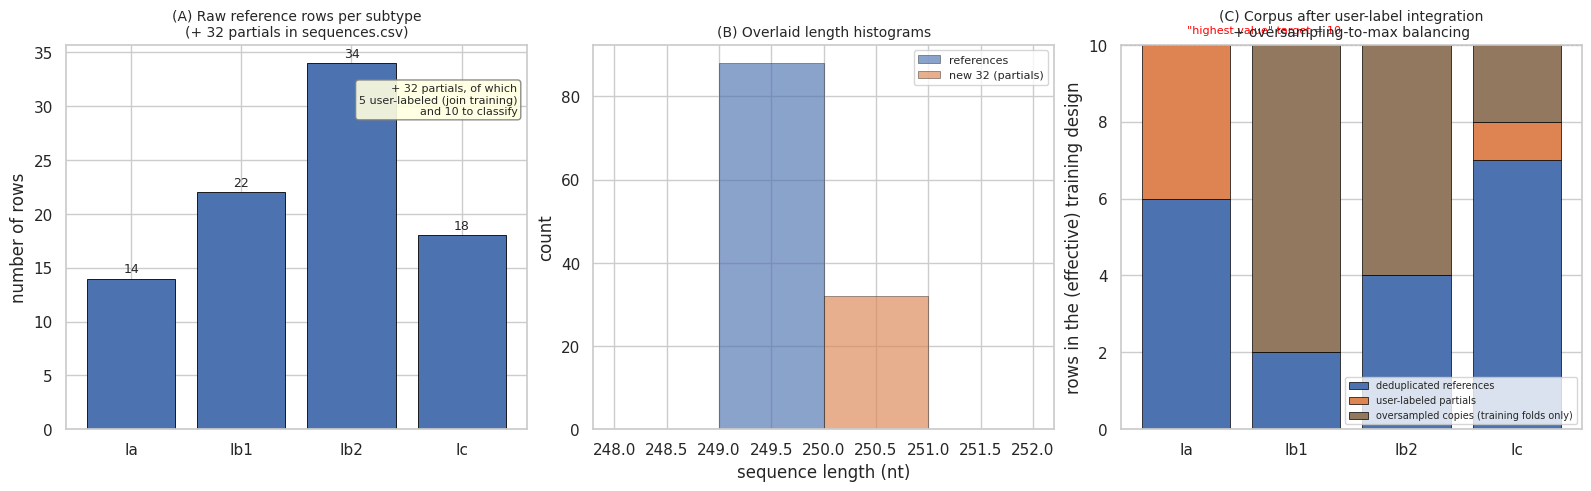

In [11]:
raw_counts = REF_DF['subtype'].value_counts().sort_index()
bal_by_sub = BALANCE_REPORT.set_index('subtype')
subtypes_o = bal_by_sub.index.tolist()
n_user = np.array([int(((CORPUS_DF['subtype'] == st) & (CORPUS_DF['provenance'] == 'user_labeled')).sum())
                   for st in subtypes_o])
n_ref = (bal_by_sub['original_rows'].values - n_user).clip(min=0)
n_cop = bal_by_sub['copies_added'].values

fig, axes = plt.subplots(1, 3, figsize=(15.8, 4.8), constrained_layout=True)
ax = axes[0]
bars = ax.bar(raw_counts.index, raw_counts.values, color='#4C72B0', edgecolor='black', linewidth=0.6)
ax.bar_label(bars, padding=2, fontsize=9)
ax.set_ylabel('number of rows')
ax.set_title('(A) Raw reference rows per subtype\n(+ 32 partials in sequences.csv)', fontsize=10)
ax.text(0.98, 0.90, f'+ {len(NEW_DF)} partials, of which\n{len(USER_LAB_DF)} user-labeled (join training)\nand {len(TO_CLASSIFY_DF)} to classify',
        transform=ax.transAxes, ha='right', va='top', fontsize=8,
        bbox=dict(boxstyle='round', fc='lightyellow', ec='gray', alpha=0.9))
ax = axes[1]
bins = np.arange(min(REF_DF['length'].min(), NEW_DF['length'].min()) - 1,
                 max(REF_DF['length'].max(), NEW_DF['length'].max()) + 3, 1)
ax.hist(REF_DF['length'], bins=bins, alpha=0.65, label='references', color='#4C72B0', edgecolor='black', linewidth=0.4)
ax.hist(NEW_DF['length'], bins=bins, alpha=0.65, label='new 32 (partials)', color='#DD8452', edgecolor='black', linewidth=0.4)
ax.set_xlabel('sequence length (nt)'); ax.set_ylabel('count')
ax.set_title('(B) Overlaid length histograms', fontsize=10)
ax.legend(fontsize=8)
ax = axes[2]
bottom = np.zeros(len(subtypes_o))
for vals, lab, col in [(n_ref, 'deduplicated references', '#4C72B0'),
                       (n_user, 'user-labeled partials', '#DD8452'),
                       (n_cop, 'oversampled copies (training folds only)', '#937860')]:
    ax.bar(subtypes_o, vals, bottom=bottom, label=lab, color=col, edgecolor='black', linewidth=0.5)
    bottom = bottom + vals
ax.axhline(TARGET_N, color='red', ls=':', lw=1.2)
ax.text(0.01, TARGET_N + 0.3, f'"highest value" target = {TARGET_N}', color='red', fontsize=8)
ax.set_ylabel('rows in the (effective) training design')
ax.set_title('(C) Corpus after user-label integration\n+ oversampling-to-max balancing', fontsize=10)
ax.legend(fontsize=7, loc='lower right')
save_and_show('fig1_data_overview.png', fig)

## STEP 3 — Feature Engineering (consumes the Step-2 preprocessed k-mers; fit only on training folds)

**Design rationale.** Two families of evidence are engineered, both length-robust because references may be full-length while queries are partial:

1. **Sequence features (3a)** — normalized k-mer frequencies (k tuned over {3,4,5}, default 4; A/C/G/T k-mers only, any k-mer overlapping an ambiguous base is skipped) — this block is **exactly the Step-2a preprocessed representation**, and an `np.allclose` assertion in Step 4b verifies the pipeline consumes it verbatim — plus **cosine similarity to each subtype's k-mer centroid** and **to the best-matching training reference of each subtype** (anchor features), **GC content**, and the **CpG observed/expected ratio** `obs(CpG)·L / (C·G)`. Normalization by valid-base count makes every feature a per-nucleotide quantity, so a 250-nt partial and a full genome live in the same space. The centroid/anchor features are computed by a custom transformer that **stores the fit-fold training rows only**, which keeps cross-validation leakage-free; the k-mer counting itself is a stateless per-sequence transform over the fixed vocabulary.
2. **Digital fingerprint features (3b)** — subtype-diagnostic k-mers mined from the training corpus (present in ≥X% of subtype *j*'s rows AND ≤Y% in every other subtype, X/Y tuned, per-subtype cap; mined from **unique sequences only** so oversampled copies cannot distort presence thresholds). For **every** sequence — corpus rows and the 10 targets — a profile `score_j = (# of mined markers of subtype j present) / (total mined markers of j)` mirrors the CSV fingerprint definition *without ever touching a label at inference time*. Mining runs inside the pipeline so each CV fold mines markers from its own training folds only.

**Schema-B adaptation (this dataset).** The CSV carries a single label-dependent self-score, so there is no "fingerprint-only" *column* set to feed a model; instead the fingerprint feature family is the **mined-marker profile** (allowed, because it is computed from sequence only). The CSV self-score still drives (a) label-noise flagging (Step 1d), (b) fig2, and (c) the Step-8 sensitivity analysis. Validation (Step 3b) checks whether the mined profiles reproduce the CSV self-scores on reference rows (per-subtype Spearman, leave-one-out mining to avoid self-inclusion bias); **if the mean r < 0.6 the notebook warns and falls back to sequence-only features for the final prediction, reporting Hybrid as an upper bound** — exactly as the protocol requires. User-labeled rows carry no CSV self-score and are excluded from that correlation by construction.

**Forbidden features** (raw length, sequence ID, header text, Schema-B self-score) are never constructed anywhere below.


In [ ]:
def _take(X, idx):
    return X.iloc[idx] if hasattr(X, 'iloc') else X[idx]

def iter_kmers(seq, k):
    for i in range(len(seq) - k + 1):
        km = seq[i:i + k]
        ok = True
        for ch in km:
            if ch not in BASES:
                ok = False
                break
        if ok:
            yield km

def kmer_counts(seq, k):
    d = {}
    for km in iter_kmers(seq, k):
        d[km] = d.get(km, 0) + 1
    return d

def kmer_freq_vec(seq, k, keys):
    c = kmer_counts(seq, k)
    tot = sum(c.values())
    if tot == 0:
        return np.zeros(len(keys))
    v = np.array([c.get(km, 0) for km in keys], dtype=float)
    return v / tot

def kmer_count_vec(seq, k, keys):
    c = kmer_counts(seq, k)
    return np.array([c.get(km, 0) for km in keys], dtype=float)

def gc_content(seq):
    s = [ch for ch in seq if ch in BASES]
    if not s:
        return 0.0
    return sum(1 for ch in s if ch in 'GC') / len(s)

def cpg_oe(seq):
    a = [ch for ch in seq if ch in BASES]
    L = len(a)
    if L < 2:
        return 0.0
    nC, nG = a.count('C'), a.count('G')
    nCG = sum(1 for i in range(L - 1) if a[i] == 'C' and a[i + 1] == 'G')
    exp = nC * nG / L
    return nCG / exp if exp > 0 else 0.0

def mine_markers(seqs, labels, k, x_thr, y_thr, cap):
    labels = np.asarray(labels)
    classes = sorted(set(labels.tolist()))
    cnt = {c: {} for c in classes}
    n = {c: 0 for c in classes}
    for s, lab in zip(seqs, labels):
        n[lab] += 1
        cc = cnt[lab]
        for km in iter_kmers(s, k):
            cc[km] = cc.get(km, 0) + 1
    rows = []
    for c in classes:
        if n[c] == 0:
            continue
        others = [o for o in classes if o != c and n[o] > 0]
        for km, cnum in cnt[c].items():
            f_in = cnum / n[c]
            if f_in < x_thr:
                continue
            f_other_max = max((cnt[o].get(km, 0) / n[o]) for o in others) if others else 0.0
            if f_other_max <= y_thr:
                rows.append((km, c, f_in, f_other_max))
    df = pd.DataFrame(rows, columns=['kmer', 'subtype', 'freq_in_subtype', 'max_freq_other_subtype'])
    if len(df):
        df = df.sort_values(['subtype', 'freq_in_subtype', 'kmer'],
                            ascending=[True, False, True], kind='mergesort')
        df = df.groupby('subtype', group_keys=False).head(cap).reset_index(drop=True)
        df['k'] = k
    return df

def marker_profile(seq, markers_df, classes):
    out = {}
    if markers_df is None or len(markers_df) == 0:
        return {c: 0.0 for c in classes}
    for c in classes:
        mks = markers_df.loc[markers_df['subtype'] == c, 'kmer'].tolist()
        if not mks:
            out[c] = 0.0
            continue
        mset = set(mks)
        mlen = len(next(iter(mset)))
        present = sum(1 for km in iter_kmers(seq, mlen) if km in mset)
        out[c] = present / len(mset)
    return out

class SequenceFeatureTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, mode='seq', k=4, marker_k=8, marker_x=0.6, marker_y=0.1, marker_cap=60, class_names=None):
        self.mode = mode; self.k = k
        self.marker_k = marker_k; self.marker_x = marker_x
        self.marker_y = marker_y; self.marker_cap = marker_cap
        self.class_names = class_names

    def fit(self, X, y=None):
        seqs = [str(s).upper() for s in X['sequence']]
        y = np.asarray(y)
        self.classes_ = np.array(sorted(set(y.tolist())))
        self.class_names_ = ([self.class_names[c] for c in self.classes_]
                             if self.class_names is not None else [f'cls{c}' for c in self.classes_])
        names = []
        self.kmer_keys_ = None; self.anchors_ = None
        self.markers_ = None; self.marker_map_ = None
        if self.mode in ('seq', 'hybrid'):
            self.kmer_keys_ = sorted({km for s in seqs for km in iter_kmers(s, self.k)})
            names += [f'k{self.k}_{km}' for km in self.kmer_keys_]
            F = np.vstack([kmer_freq_vec(s, self.k, self.kmer_keys_) for s in seqs])
            self.anchors_ = {}
            for c in self.classes_:
                idx = np.where(y == c)[0]
                self.anchors_[c] = F[idx].mean(axis=0), F[idx]
            names += [f'cos_centroid_{c}' for c in self.class_names_]
            names += [f'bestref_cos_{c}' for c in self.class_names_]
            names += ['gc_content', 'cpg_oe']
        elif self.mode == 'counts':
            self.kmer_keys_ = sorted({km for s in seqs for km in iter_kmers(s, self.k)})
            names += [f'count_k{self.k}_{km}' for km in self.kmer_keys_]
        if self.mode in ('fp', 'hybrid'):
            _, first_uniq = np.unique(np.asarray(seqs), return_index=True)
            keep = np.sort(first_uniq)
            self.markers_ = mine_markers([seqs[i] for i in keep], y[keep], self.marker_k,
                                         self.marker_x, self.marker_y, self.marker_cap)
            self.marker_map_ = {c: [] for c in self.classes_}
            if len(self.markers_):
                for c, grp in self.markers_.groupby('subtype'):
                    if c in self.marker_map_:
                        self.marker_map_[c] = list(grp['kmer'])
            names += [f'fpmined_{c}' for c in self.class_names_]
        self.feature_names_ = names
        return self

    def transform(self, X):
        seqs = [str(s).upper() for s in X['sequence']]
        n = len(seqs)
        out = {}
        if self.mode in ('seq', 'hybrid'):
            F = np.vstack([kmer_freq_vec(s, self.k, self.kmer_keys_) for s in seqs])
            for j, km in enumerate(self.kmer_keys_):
                out[f'k{self.k}_{km}'] = F[:, j]
            nrm = np.linalg.norm(F, axis=1); nrm[nrm == 0] = 1.0
            Fn = F / nrm[:, None]
            for j, c in enumerate(self.classes_):
                cen, sub = self.anchors_[c]
                cn = np.linalg.norm(cen)
                out[f'cos_centroid_{self.class_names_[j]}'] = Fn @ (cen / cn) if cn > 0 else np.zeros(n)
                sn = np.linalg.norm(sub, axis=1); sn[sn == 0] = 1.0
                sims = Fn @ (sub / sn[:, None]).T
                out[f'bestref_cos_{self.class_names_[j]}'] = sims.max(axis=1)
            out['gc_content'] = np.array([gc_content(s) for s in seqs])
            out['cpg_oe'] = np.array([cpg_oe(s) for s in seqs])
        if self.mode in ('fp', 'hybrid'):
            for j, c in enumerate(self.classes_):
                mks = self.marker_map_[c]
                vals = np.zeros(n)
                if mks:
                    mset = set(mks); mlen = len(next(iter(mset)))
                    for i, s in enumerate(seqs):
                        present = sum(1 for km in iter_kmers(s, mlen) if km in mset)
                        vals[i] = present / len(mset)
                out[f'fpmined_{self.class_names_[j]}'] = vals
        if self.mode == 'counts':
            C = np.vstack([kmer_count_vec(s, self.k, self.kmer_keys_) for s in seqs])
            for j, km in enumerate(self.kmer_keys_):
                out[f'count_k{self.k}_{km}'] = C[:, j]
        return pd.DataFrame(out, columns=self.feature_names_, index=X.index)

    def get_feature_names(self):
        return list(getattr(self, 'feature_names_', []))

class CalibratedSVC(BaseEstimator, ClassifierMixin):
    def __init__(self, kernel='rbf', C=1.0, gamma='scale', class_weight=None, method='sigmoid', random_state=42):
        self.kernel = kernel; self.C = C; self.gamma = gamma
        self.class_weight = class_weight; self.method = method; self.random_state = random_state

    def fit(self, X, y):
        y = np.asarray(y)
        self.classes_ = np.array(sorted(set(y.tolist())))
        min_class = int(pd.Series(y).value_counts().min())
        svc = SVC(kernel=self.kernel, C=self.C, gamma=self.gamma,
                  class_weight=self.class_weight, random_state=self.random_state)
        self.calibrated_ = False
        if min_class >= 2:
            try:
                self.model_ = CalibratedClassifierCV(svc, method=self.method, cv=int(min(5, min_class))).fit(X, y)
                self.calibrated_ = True
                return self
            except Exception as e:
                pass
        self.model_ = svc.fit(X, y)
        return self

    def predict(self, X):
        return self.model_.predict(X)

    def predict_proba(self, X):
        if self.calibrated_:
            return self.model_.predict_proba(X)
        d = self.model_.decision_function(X)
        e = np.exp(d - d.max(axis=1, keepdims=True))
        return e / e.sum(axis=1, keepdims=True)

def build_transformer(mode=None, k=None, class_names=None):
    mode = mode or FINAL_FEATURESET if 'FINAL_FEATURESET' in globals() else (mode or 'seq')
    k = k or (CHOSEN_K if 'CHOSEN_K' in globals() else KMER_K_DEFAULT)
    return SequenceFeatureTransformer(mode=mode, k=k, marker_k=MARKER_K_CH, marker_x=MARKER_X_CH,
                                      marker_y=MARKER_Y_CH, marker_cap=MARKER_CAP,
                                      class_names=class_names if class_names is not None else
                                      (CLASSES if 'CLASSES' in globals() else None))

def oof_predict_proba(est, X, y, splits, classes):
    classes = np.asarray(classes)
    P = np.full((len(y), len(classes)), np.nan)
    times = []
    for tr, te in splits:
        t0 = time.time()
        m = clone(est).fit(_take(X, tr), y[tr])
        times.append(time.time() - t0)
        pp = m.predict_proba(_take(X, te))
        cols = [int(np.where(classes == c)[0][0]) for c in m.classes_]
        P[np.ix_(np.asarray(te, dtype=int), cols)] = pp
    return P, np.array(times)

In [13]:
CLASSES = sorted(CORPUS_DF['subtype'].unique())
le = LabelEncoder().fit(CLASSES)

corp_seqs = CORPUS_DF['sequence'].tolist()
corp_labs = CORPUS_DF['subtype'].values

sweep_rows = []
for K in MARKER_K_GRID:
    for X_ in MARKER_X_GRID:
        for Y_ in MARKER_Y_GRID:
            mk = mine_markers(corp_seqs, corp_labs, K, X_, Y_, MARKER_CAP)
            counts = mk.groupby('subtype').size().reindex(CLASSES).fillna(0).astype(int)
            sweep_rows.append({'k': K, 'X': X_, 'Y': Y_, 'n_subtypes_covered': int((counts > 0).sum()),
                               'total_markers': int(counts.sum()), **{f'n_{c}': int(counts[c]) for c in CLASSES}})
SWEEP_DF = pd.DataFrame(sweep_rows)
SWEEP_DF['dist_to_defaults'] = (SWEEP_DF['X'] - 0.8).abs() + (SWEEP_DF['Y'] - 0.1).abs()
SWEEP_DF = SWEEP_DF.sort_values(['n_subtypes_covered', 'total_markers', 'dist_to_defaults', 'k'],
                                ascending=[False, False, True, True]).reset_index(drop=True)
display(SWEEP_DF.head(12))
best = SWEEP_DF.iloc[0]
MARKER_K_CH, MARKER_X_CH, MARKER_Y_CH = int(best['k']), float(best['X']), float(best['Y'])
if int(best['n_subtypes_covered']) < len(CLASSES):
    missing = [c for c in SWEEP_DF.columns if c.startswith('n_') and best[c] == 0]

,k,X,Y,n_subtypes_covered,total_markers,n_Ia,n_Ib1,n_Ib2,n_Ic,dist_to_defaults
0,8,0.6,0.2,3,25,8,0,9,8,0.3
1,8,0.6,0.3,3,25,8,0,9,8,0.4
2,7,0.6,0.2,3,22,7,0,8,7,0.3
3,7,0.6,0.3,3,22,7,0,8,7,0.4
4,6,0.6,0.2,3,17,5,0,6,6,0.3
5,6,0.6,0.3,3,17,5,0,6,6,0.4
6,5,0.6,0.3,3,11,3,0,4,4,0.4
7,5,0.6,0.2,3,10,2,0,4,4,0.3
8,4,0.6,0.3,3,5,1,0,2,2,0.4
9,8,0.6,0.1,2,9,0,0,1,8,0.2


In [14]:
val_rows = []
for i in range(len(CORPUS_DF)):
    seqs_o = [s for j, s in enumerate(corp_seqs) if j != i]
    labs_o = [l for j, l in enumerate(corp_labs) if j != i]
    mk_o = mine_markers(seqs_o, labs_o, MARKER_K_CH, MARKER_X_CH, MARKER_Y_CH, MARKER_CAP)
    prof = marker_profile(corp_seqs[i], mk_o, CLASSES)
    own_st = corp_labs[i]
    val_rows.append({'corpus_id': CORPUS_DF['corpus_id'].iloc[i],
                     'provenance': CORPUS_DF['provenance'].iloc[i],
                     'subtype': own_st,
                     'csv_fp_score': CORPUS_DF['fp_frac'].iloc[i],
                     'mined_own_score': prof[own_st],
                     'n_markers_own_subtype': 0 if len(mk_o) == 0 else int((mk_o['subtype'] == own_st).sum())})
VAL_DF = pd.DataFrame(val_rows)

rows_rs = []
for st in CLASSES:
    sub = VAL_DF[VAL_DF['subtype'] == st]
    ok = sub['mined_own_score'].notna() & sub['csv_fp_score'].notna() & sub['n_markers_own_subtype'] > 0
    if ok.sum() >= 3 and sub.loc[ok, 'mined_own_score'].nunique() > 1 and sub.loc[ok, 'csv_fp_score'].nunique() > 1:
        r, p = spearmanr(sub.loc[ok, 'csv_fp_score'], sub.loc[ok, 'mined_own_score'])
        rows_rs.append({'subtype': st, 'n': int(ok.sum()), 'spearman_r': float(r), 'p_value': float(p)})
    else:
        why = ('no mined markers' if (sub['n_markers_own_subtype'] > 0).sum() == 0 else
               'constant mined score / too few reference rows with a CSV score')
        rows_rs.append({'subtype': st, 'n': int(ok.sum()), 'spearman_r': np.nan, 'p_value': np.nan,
                        'note': why})
VALID_RS = pd.DataFrame(rows_rs)
defined = VALID_RS['spearman_r'].dropna()
MARKERS_VALID = bool(len(defined) >= FP_VALID_MIN_NSUB and defined.mean() >= FP_VALID_R_MIN)
if 'note' not in VALID_RS.columns:
    VALID_RS['note'] = ''
display(VALID_RS)

,subtype,n,spearman_r,p_value,note
0,Ia,0,NaN,NaN,constant mined score / too few reference rows ...
1,Ib1,0,NaN,NaN,constant mined score / too few reference rows ...
2,Ib2,4,0.774597,0.225403,NaN
3,Ic,0,NaN,NaN,constant mined score / too few reference rows ...


[mined_markers.csv] written: 25 diagnostic 8-mers ({'Ia': 8, 'Ib2': 9, 'Ic': 8}).


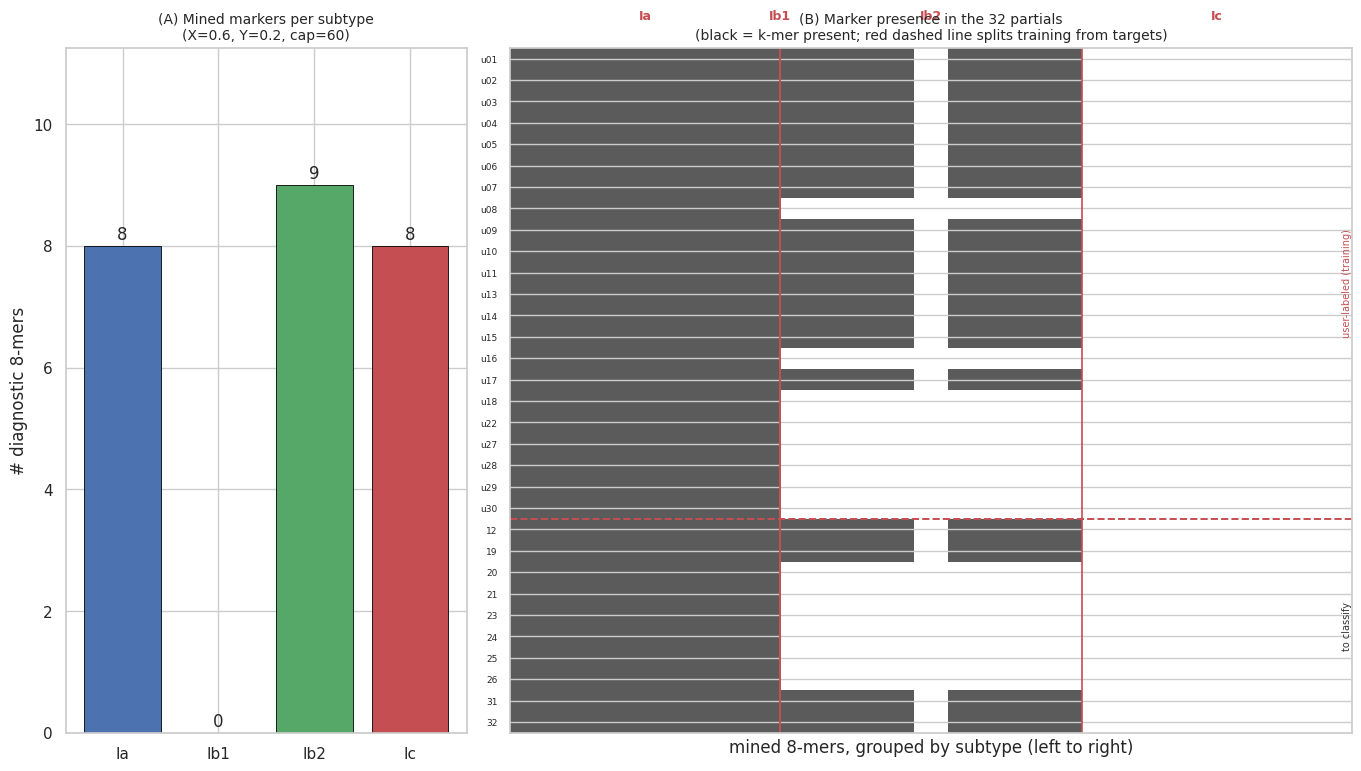

In [15]:
MARKERS_FULL = mine_markers(corp_seqs, corp_labs, MARKER_K_CH, MARKER_X_CH, MARKER_Y_CH, MARKER_CAP)
MARKERS_FULL.to_csv(os.path.join(OUTDIR, 'mined_markers.csv'), index=False)
print(f'[mined_markers.csv] written: {len(MARKERS_FULL)} diagnostic {MARKER_K_CH}-mers '
      f'({MARKERS_FULL.groupby("subtype").size().to_dict() if len(MARKERS_FULL) else "none"}).')

prof_rows = []
for i, s in enumerate(NEW_DF['sequence']):
    n = int(NEW_DF['new_id'].iloc[i])
    row = {'seq_id': str(n),
           'group': 'user_labeled_train' if n in USER_LABEL_MAP else 'to_classify',
           'user_label': USER_LABEL_MAP.get(n, np.nan)}
    row.update(marker_profile(s, MARKERS_FULL, CLASSES))
    prof_rows.append(row)
NEW_PROFILES = pd.DataFrame(prof_rows)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 7.6), constrained_layout=True,
                         gridspec_kw={'width_ratios': [1, 2.1]})
ax = axes[0]
cnts = MARKERS_FULL.groupby('subtype').size().reindex(CLASSES).fillna(0) if len(MARKERS_FULL) else pd.Series(0, index=CLASSES)
bars = ax.bar(cnts.index, cnts.values, color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'][:len(CLASSES)],
              edgecolor='black', linewidth=0.6)
ax.bar_label(bars, padding=2)
ax.set_ylabel(f'# diagnostic {MARKER_K_CH}-mers')
ax.set_title(f'(A) Mined markers per subtype\n(X={MARKER_X_CH}, Y={MARKER_Y_CH}, cap={MARKER_CAP})', fontsize=10)
ax.set_ylim(0, max(1, cnts.max() * 1.25))
ax = axes[1]
if len(MARKERS_FULL):
    order_nums = sorted([n for n in NEW_DF['new_id'].astype(int) if n in USER_LABEL_MAP]) + \
                 sorted([n for n in NEW_DF['new_id'].astype(int) if n not in USER_LABEL_MAP])
    num2seq = dict(zip(NEW_DF['new_id'].astype(int), NEW_DF['sequence']))
    mlist = MARKERS_FULL['kmer'].tolist()
    pres = np.zeros((len(order_nums), len(mlist)))
    for i, n in enumerate(order_nums):
        sk = set(sequence_to_kmers(num2seq[n], MARKER_K_CH))
        for jj, m in enumerate(mlist):
            pres[i, jj] = 1.0 if m in sk else 0.0
    im = ax.imshow(pres, aspect='auto', cmap='Greys', vmin=0, vmax=1.4)
    bounds, cum = [], 0
    for c in CLASSES:
        cum += int((MARKERS_FULL['subtype'] == c).sum())
        bounds.append(cum - 0.5)
    for b in bounds[:-1]:
        ax.axvline(b, color='#C44E52', lw=1.2)
    offs, cum = [], 0
    for c in CLASSES:
        w = int((MARKERS_FULL['subtype'] == c).sum())
        offs.append(cum + w / 2 - 0.5); cum += w
    for off, c in zip(offs, CLASSES):
        ax.text(off, -2.0, c, ha='center', va='center', fontsize=9, color='#C44E52', fontweight='bold')
    n_user_block = sum(1 for n in order_nums if n in USER_LABEL_MAP)
    ax.axhline(n_user_block - 0.5, color='#C44E52', lw=1.4, ls='--')
    ax.text(len(mlist) - 0.5, n_user_block / 2 - 0.5, 'user-labeled (training)', rotation=90,
            ha='right', va='center', fontsize=7, color='#C44E52')
    ax.text(len(mlist) - 0.5, n_user_block + (len(order_nums) - n_user_block) / 2 - 0.5, 'to classify',
            rotation=90, ha='right', va='center', fontsize=7, color='#333333')
    ax.set_yticks(range(len(order_nums)))
    ax.set_yticklabels([f'u{n:02d}' if n in USER_LABEL_MAP else str(n) for n in order_nums], fontsize=6.5)
    ax.set_xticks([])
    ax.set_xlabel(f'mined {MARKER_K_CH}-mers, grouped by subtype (left to right)')
    ax.set_title('(B) Marker presence in the 32 partials\n(black = k-mer present; red dashed line splits training from targets)', fontsize=10)
else:
    ax.text(0.5, 0.5, 'no markers mined', ha='center', va='center', transform=ax.transAxes)
    ax.axis('off')
save_and_show('fig13_markers.png', fig)

## STEP 4 — Evaluation Protocol (combined corpus, fold-safe balancing)

**Protocol, exactly as pre-specified — now over the preprocessed corpus.** A stratified **80/20 hold-out** (`random_state=42`) of the **combined corpus** (deduplicated references + user-labeled partials) is reserved for final evaluation; and because the protocol says **"if any subtype has <20 references use LOOCV and say so"**, the CV engine below checks the minimum per-subtype count on the **original** rows and switches to **Leave-One-Out** accordingly (announced explicitly when it does). Grid search optimizes **`balanced_accuracy`** (the macro-oriented metric). All feature construction, scaling, mining, calibration and tuning happen strictly inside the training folds — the hold-out rows and the 10 to-classify partials never influence any fitting step.

**Fold-safe balancing (the "pick the highest value" rule, applied correctly).** After the hold-out split, the **training split alone** is augmented by `make_balanced_augment` (Step 2c): every subtype is oversampled with replacement up to the **highest per-subtype count** in that split, originals first, copies after. CV then runs over `splits_balanced` split lists whose **validation folds contain original rows only** — each original row is validated exactly once — while each **training** fold = its original rows + all synthetic copies whose parent lies in-fold. Consequently: (i) no model is ever graded on a sequence (or a copy of a sequence) it trained on; (ii) every training fold is *balanced by design*; (iii) OOF metrics are computed **on original rows only**, with the augmented fit-times still measured per fold. Two small-sample guards are applied and disclosed: (i) the stratified split is adjusted if the training partition would receive <2 rows of some subtype (calibration and stratified CV require it); (ii) sigmoid calibration uses an adaptive inner fold count (never more than the smallest class supports), with a softmax-on-decision-function fallback that is announced if it ever fires.

Every model — SVM, all benchmarks, the biology baselines and both ensembles — flows through the **same** `evaluate_model()` engine and is reported in an **identical format**: best params → pooled out-of-fold CV metrics (accuracy, balanced accuracy, macro-F1, one-vs-rest ROC-AUC, multiclass Brier) → held-out classification report → raw + row-normalized confusion-matrix figure → probability table for the 10 targets (Step 8). Out-of-fold predictions are produced by `oof_predict_proba` under the protocol's fold-safe split lists, keeping metric definitions identical across models.


In [ ]:
X_ORIG_DF = pd.DataFrame({'sequence': CORPUS_DF['sequence'].values},
                         index=CORPUS_DF['corpus_id'].values)
Y_ORIG = le.transform(CORPUS_DF['subtype'].values)
ORIG_META = CORPUS_DF[['corpus_id', 'provenance', 'subtype']].reset_index(drop=True)

all_idx = np.arange(len(X_ORIG_DF))
tr_idx, te_idx = train_test_split(all_idx, test_size=TEST_SIZE, stratify=Y_ORIG, random_state=RANDOM_STATE)

moved = []
tr_counts = Counter(Y_ORIG[tr_idx])
for c in range(len(CLASSES)):
    while tr_counts[c] < 2:
        cand = [i for i in te_idx if Y_ORIG[i] == c]
        if not cand:
            break
        mv = cand[0]
        te_idx = np.array([i for i in te_idx if i != mv])
        tr_idx = np.array(list(tr_idx) + [mv])
        tr_counts = Counter(Y_ORIG[tr_idx])
        moved.append((ORIG_META['corpus_id'].iloc[mv], CLASSES[c]))

X_TR_ORIG = X_ORIG_DF.iloc[tr_idx]
Y_TR_ORIG = Y_ORIG[tr_idx]
X_TEST_DF = X_ORIG_DF.iloc[te_idx]
Y_TEST = Y_ORIG[te_idx]

X_TRAIN_DF, Y_TRAIN, TRAIN_COPY_OF, N_TRAIN_ORIG = make_balanced_augment(X_TR_ORIG, Y_TR_ORIG, seed=RANDOM_STATE)
Y_TRAIN_EVAL = Y_TR_ORIG.copy()

min_class_full = int(pd.Series(Y_ORIG).value_counts().min())
min_class_train = int(pd.Series(Y_TR_ORIG).value_counts().min())
CV_MODE = 'loo' if min_class_full < 20 else 'stratified'
CV_SPLITS = splits_balanced(N_TRAIN_ORIG, TRAIN_COPY_OF, mode=CV_MODE, y_orig=Y_TR_ORIG,
                            n_splits=5, seed=RANDOM_STATE)
CV_TUNE_SPLITS = splits_balanced(N_TRAIN_ORIG, TRAIN_COPY_OF,
                                 mode=('loo' if min_class_train < 5 else 'stratified'),
                                 y_orig=Y_TR_ORIG, n_splits=5, seed=RANDOM_STATE)
aug_counts = Counter(Y_TRAIN.tolist())

In [17]:
def make_probe(mode, k):
    return Pipeline([
        ('feat', SequenceFeatureTransformer(mode=mode, k=k, marker_k=MARKER_K_CH, marker_x=MARKER_X_CH,
                                            marker_y=MARKER_Y_CH, marker_cap=MARKER_CAP, class_names=CLASSES)),
        ('clf', Pipeline([('scale', StandardScaler()),
                          ('m', CalibratedSVC(kernel='linear', C=1.0, class_weight='balanced',
                                              random_state=RANDOM_STATE))]))])

def pooled_metrics(y_true, P):
    pred = P.argmax(axis=1)
    try:
        auc = roc_auc_score(y_true, P, multi_class='ovr', average='macro', labels=list(range(len(CLASSES))))
    except Exception:
        auc = np.nan
    Yb = label_binarize(y_true, classes=list(range(len(CLASSES))))
    brier = float(np.mean(np.sum((P - Yb) ** 2, axis=1)))
    return {'accuracy': float(accuracy_score(y_true, pred)),
            'balanced_accuracy': float(balanced_accuracy_score(y_true, pred)),
            'macro_f1': float(f1_score(y_true, pred, average='macro', zero_division=0)),
            'roc_auc_ovr': float(auc), 'brier_multiclass': brier}

def oof_probe(mode, k):
    P_full, _t = oof_predict_proba(make_probe(mode, k), X_TRAIN_DF, Y_TRAIN, CV_SPLITS,
                                   np.arange(len(CLASSES)))
    return P_full[:N_TRAIN_ORIG]

k_rows = []
for k in KMER_K_CANDIDATES:
    P = oof_probe('seq', k)
    m = pooled_metrics(Y_TRAIN_EVAL, P)
    k_rows.append({'k': k, **m, 'default': (k == KMER_K_DEFAULT)})
K_TABLE = pd.DataFrame(k_rows)
display(K_TABLE.round(3))
best_k_row = K_TABLE.sort_values(['balanced_accuracy', 'default'], ascending=[False, False]).iloc[0]
CHOSEN_K = int(best_k_row['k'])

chk_feat = build_transformer('seq', k=CHOSEN_K).fit(X_TRAIN_DF, Y_TRAIN)
chk_block = chk_feat.transform(X_ORIG_DF)
obs_keys = chk_feat.kmer_keys_
col_idx = [VOCABS[CHOSEN_K].index(km) for km in obs_keys]
uid_of = {cid: (cid if str(cid).startswith('ref_') else f'n{int(str(cid)[1:]):02d}') for cid in X_ORIG_DF.index}
M_pipe = chk_block[[f'k{CHOSEN_K}_{km}' for km in obs_keys]].values
M_pre = np.vstack([KMER_FREQ[uid_of[cid]][CHOSEN_K][col_idx] for cid in X_ORIG_DF.index])
assert np.allclose(M_pipe, M_pre, atol=1e-12), 'pipeline k-mer block != Step-2 preprocessed matrix!'

fs_rows = []
for mode, desc in [('seq', 'sequence-only (preprocessed k-mer freqs + centroid/anchor cosines + GC + CpG)'),
                   ('fp', 'fingerprint-only (mined diagnostic-marker profile — Schema-B adaptation)'),
                   ('hybrid', 'Hybrid = sequence + mined fingerprint profile')]:
    P = oof_probe(mode, CHOSEN_K)
    m = pooled_metrics(Y_TRAIN_EVAL, P)
    fs_rows.append({'feature_set': mode, 'description': desc, **m})
FS_TABLE = pd.DataFrame(fs_rows)
display(FS_TABLE[['feature_set', 'accuracy', 'balanced_accuracy', 'macro_f1', 'roc_auc_ovr', 'brier_multiclass']].round(3))
FS_TABLE.to_csv(os.path.join(OUTDIR, 'feature_set_comparison.csv'), index=False)
print('[feature_set_comparison.csv] written.')

seq_ba = float(FS_TABLE.loc[FS_TABLE.feature_set == 'seq', 'balanced_accuracy'].iloc[0])
fp_ba = float(FS_TABLE.loc[FS_TABLE.feature_set == 'fp', 'balanced_accuracy'].iloc[0])
hyb_ba = float(FS_TABLE.loc[FS_TABLE.feature_set == 'hybrid', 'balanced_accuracy'].iloc[0])
if MARKERS_VALID:
    FINAL_FEATURESET = 'hybrid' if hyb_ba > seq_ba + 0.01 else 'seq'
    why = ('mined markers VALID; Hybrid chosen only if it clearly beats sequence-only (>0.01 CV balanced accuracy), '
           'else the parsimonious sequence-only set is preferred')
else:
    FINAL_FEATURESET = 'seq'
    why = 'mined markers FAILED validation (mean Spearman r < 0.6 or too few defined subtypes) -> protocol fallback to sequence-only'

,k,accuracy,balanced_accuracy,macro_f1,roc_auc_ovr,brier_multiclass,default
0,3,0.789,0.865,0.821,0.869,0.513,False
1,4,0.789,0.771,0.765,0.909,0.481,True
2,5,0.684,0.625,0.599,0.854,0.511,False


,feature_set,accuracy,balanced_accuracy,macro_f1,roc_auc_ovr,brier_multiclass
0,seq,0.789,0.865,0.821,0.869,0.513
1,fp,0.842,0.802,0.792,0.799,0.396
2,hybrid,0.789,0.781,0.768,0.921,0.492


[feature_set_comparison.csv] written.


In [ ]:
MODEL_ROWS, CM_ROWS = [], []
RESULTS = {}
FITTED = {}
OOF_STORE = {}

def _confusion_figure(key, display_name, cm, cm_norm):
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), constrained_layout=True)
    for ax, mat, ttl, fmt in [(axes[0], cm, 'raw counts', 'd'),
                              (axes[1], cm_norm, 'row-normalized (recall per true subtype)', '.2f')]:
        if HAS_SNS:
            sns.heatmap(mat, annot=True, fmt=fmt, cmap='Blues', cbar=False,
                        xticklabels=CLASSES, yticklabels=CLASSES, ax=ax,
                        annot_kws={'fontsize': 9}, linewidths=0.4, linecolor='white')
        else:
            ax.imshow(mat, cmap='Blues')
            for i in range(mat.shape[0]):
                for j in range(mat.shape[1]):
                    ax.text(j, i, format(mat[i, j], fmt), ha='center', va='center', fontsize=9)
            ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES)
            ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
        ax.set_xlabel('predicted subtype'); ax.set_ylabel('true subtype')
        ax.set_title(ttl, fontsize=9.5)
    fig.suptitle(f'{display_name} — held-out confusion matrices', fontsize=11)
    save_and_show(f'fig4_{key}_confusion_matrix.png', fig)

def evaluate_model(key, display_name, tier, builder, grid=None, oof_enabled=True, feature_set=None):
    """Fit/tune -> pooled OOF CV metrics -> held-out report -> confusion figure. Identical output for all models."""
    feature_set = feature_set or (FINAL_FEATURESET if key != 'b2_fingerprint_baseline' else 'fp')
    est = builder(feature_set) if feature_set else builder()
    t0 = time.time()
    if grid:
        gs = GridSearchCV(est, grid, scoring='balanced_accuracy', cv=CV_TUNE_SPLITS, refit=True,
                          error_score=np.nan, n_jobs=1)
        gs.fit(X_TRAIN_DF, Y_TRAIN)
        best = gs.best_estimator_
        bidx = int(np.nanargmax(gs.cv_results_['mean_test_score']))
        fit_time = float(gs.cv_results_['mean_fit_time'][bidx])
        best_params = {k.replace('clf__m__', ''): v for k, v in gs.best_params_.items()}
        n_cand = len(gs.cv_results_['params'])
    else:
        best = est.fit(X_TRAIN_DF, Y_TRAIN)
        fit_time = time.time() - t0
        best_params, n_cand = {}, 0
    FITTED[key] = best

    oof = None
    if oof_enabled:
        P_full, fold_times = oof_predict_proba(clone(best), X_TRAIN_DF, Y_TRAIN, CV_SPLITS,
                                               np.arange(len(CLASSES)))
        oof = P_full[:N_TRAIN_ORIG]
        cvm = pooled_metrics(Y_TRAIN_EVAL, oof)
        OOF_STORE[key] = (Y_TRAIN_EVAL.copy(), oof)
    else:
        cvm = {k_: np.nan for k_ in ['accuracy', 'balanced_accuracy', 'macro_f1', 'roc_auc_ovr', 'brier_multiclass']}
        OOF_STORE[key] = None
        fold_times = np.array([fit_time])

    pred_te = best.predict(X_TEST_DF)
    P_te = best.predict_proba(X_TEST_DF)
    ho = pooled_metrics(Y_TEST, P_te)
    rep = classification_report(Y_TEST, pred_te, labels=list(range(len(CLASSES))),
                                target_names=CLASSES, output_dict=True, zero_division=0)
    cm = confusion_matrix(Y_TEST, pred_te, labels=list(range(len(CLASSES))))
    with np.errstate(divide='ignore', invalid='ignore'):
        cm_norm = cm / cm.sum(axis=1, keepdims=True)
    cm_norm = np.nan_to_num(cm_norm)
    _confusion_figure(key, display_name, cm, cm_norm)
    for i, ts in enumerate(CLASSES):
        for j, ps in enumerate(CLASSES):
            CM_ROWS.append({'model': key, 'true_subtype': ts, 'pred_subtype': ps,
                            'count': int(cm[i, j]), 'row_normalized': float(cm_norm[i, j])})

    RESULTS[key] = dict(key=key, name=display_name, tier=tier, feature_set=feature_set,
                        best_params=best_params, n_candidates=n_cand,
                        cv_accuracy=cvm['accuracy'], cv_bal_acc=cvm['balanced_accuracy'],
                        cv_macro_f1=cvm['macro_f1'], cv_roc_auc=cvm['roc_auc_ovr'], cv_brier=cvm['brier_multiclass'],
                        ho_accuracy=ho['accuracy'], ho_bal_acc=ho['balanced_accuracy'],
                        ho_macro_f1=ho['macro_f1'], ho_roc_auc=ho['roc_auc_ovr'], ho_brier=ho['brier_multiclass'],
                        fold_times=fold_times, rep=rep, oof=oof, best_est=best)

    if oof_enabled:
        cvname = 'fold-safe LOOCV' if CV_MODE == 'loo' else 'fold-safe 5-fold stratified'
    rep_df = pd.DataFrame(rep).T.rename(
        columns={'precision': 'precision', 'recall': 'recall', 'f1-score': 'F1', 'support': 'support'})
    return RESULTS[key]

def bootstrap_ci_oof(key, metric_fn, n_boot=N_BOOT, seed=RANDOM_STATE):
    o = OOF_STORE.get(key)
    if o is None:
        return np.nan, np.nan
    y, P = o
    rng = np.random.default_rng(seed)
    vals = []
    n = len(y)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        vals.append(metric_fn(y[idx], P[idx]))
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return float(lo), float(hi)

## STEP 5 — Primary Model: Support Vector Machine (calibrated)

**Why an SVM is the right primary model here.** With ~250-nt sequences the discriminative signal lives in a sparse, high-dimensional k-mer space (hundreds of near-independent coordinates, most of them zero for any given read). Maximal-margin classifiers are the classical, well-behaved choice in exactly this regime: (i) the **linear** kernel behaves like a regularized (primal) logistic scoring of k-mer evidence and is strong when the classes are linearly separable by a few SNPs; (ii) the **RBF** kernel can capture local *epistatic* combinations of positions (a lineage defined by an allele *combination* rather than a single SNP); (iii) the **polynomial** kernel covers intermediate interactions. Residual imbalance is handled on two levels: the fold-safe Step-2 balancing already makes every training fold *effectively even* (each subtype at the highest per-subtype count), and `class_weight='balanced'` is still swept alongside `None` as the pre-registered belt-and-braces measure. The grid spans C (margin softness) over three orders of magnitude and gamma (RBF/poly locality) over {scale, 0.01, 0.1, 1}. The pipeline is `SequenceFeatureTransformer → StandardScaler → CalibratedClassifierCV(SVC, method='sigmoid')`; sigmoid calibration (inner CV adaptive to the smallest class, per Step 4) turns margin scores into **per-subtype probabilities**, which Step 8 requires. Tuning: `GridSearchCV(scoring='balanced_accuracy', cv=<fold-safe protocol CV>)`. γ is not swept for the linear kernel (it has no effect there), which is disclosed rather than hidden.


In [19]:
SVM_GRID = [
    {'clf__m__kernel': ['linear'], 'clf__m__C': [0.1, 1, 10, 100],
     'clf__m__class_weight': [None, 'balanced']},
    {'clf__m__kernel': ['rbf', 'poly'], 'clf__m__C': [0.1, 1, 10, 100],
     'clf__m__gamma': ['scale', 0.01, 0.1, 1], 'clf__m__class_weight': [None, 'balanced']},
]

def _ml_builder(core_factory, mode=None):
    def _b(fs=None):
        fs = fs or FINAL_FEATURESET
        return Pipeline([('feat', build_transformer(fs)),
                         ('clf', Pipeline([('scale', StandardScaler()), ('m', core_factory())]))])
    return _b

MODELS = {}
MODELS['svm'] = dict(
    name='SVM (calibrated, primary)', tier='primary',
    builder=_ml_builder(lambda: CalibratedSVC(random_state=RANDOM_STATE)),
    grid=SVM_GRID,
    make_core=lambda p: CalibratedSVC(kernel=p.get('kernel', 'rbf'), C=p.get('C', 1.0),
                                      gamma=p.get('gamma', 'scale'), class_weight=p.get('class_weight', None),
                                      random_state=RANDOM_STATE))

MODELS['logreg'] = dict(
    name='Logistic Regression (multinomial)', tier='benchmark',
    builder=_ml_builder(lambda: LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    grid=[{'clf__m__C': [0.01, 0.1, 1, 10, 100], 'clf__m__class_weight': [None, 'balanced']}],
    make_core=lambda p: LogisticRegression(max_iter=5000, C=p.get('C', 1.0),
                                           class_weight=p.get('class_weight', None), random_state=RANDOM_STATE))

MODELS['random_forest'] = dict(
    name='Random Forest', tier='benchmark',
    builder=_ml_builder(lambda: RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1)),
    grid=[{'clf__m__max_depth': [None, 10], 'clf__m__min_samples_leaf': [1, 2],
           'clf__m__class_weight': [None, 'balanced']}],
    make_core=lambda p: RandomForestClassifier(n_estimators=200, max_depth=p.get('max_depth', None),
                                               min_samples_leaf=p.get('min_samples_leaf', 1),
                                               class_weight=p.get('class_weight', None),
                                               random_state=RANDOM_STATE, n_jobs=1))

MODELS['extra_trees'] = dict(
    name='Extra Trees', tier='benchmark',
    builder=_ml_builder(lambda: ExtraTreesClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1)),
    grid=[{'clf__m__max_depth': [None, 10], 'clf__m__min_samples_leaf': [1, 2],
           'clf__m__class_weight': [None, 'balanced']}],
    make_core=lambda p: ExtraTreesClassifier(n_estimators=200, max_depth=p.get('max_depth', None),
                                             min_samples_leaf=p.get('min_samples_leaf', 1),
                                             class_weight=p.get('class_weight', None),
                                             random_state=RANDOM_STATE, n_jobs=1))

if HAS_LGBM:
    MODELS['gbm'] = dict(
        name='Gradient Boosting (LightGBM backend)', tier='benchmark',
        builder=_ml_builder(lambda: LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1,
                                                   min_child_samples=1)),
        grid=[{'clf__m__n_estimators': [100, 200], 'clf__m__learning_rate': [0.05, 0.1],
               'clf__m__num_leaves': [7, 15]}],
        make_core=lambda p: LGBMClassifier(n_estimators=p.get('n_estimators', 100),
                                           learning_rate=p.get('learning_rate', 0.1),
                                           num_leaves=p.get('num_leaves', 7), min_child_samples=1,
                                           random_state=RANDOM_STATE, n_jobs=1, verbose=-1))
elif HAS_XGB:
    MODELS['gbm'] = dict(
        name='Gradient Boosting (XGBoost backend)', tier='benchmark',
        builder=_ml_builder(lambda: XGBClassifier(random_state=RANDOM_STATE, n_jobs=1, eval_metric='mlogloss')),
        grid=[{'clf__m__n_estimators': [100, 200], 'clf__m__learning_rate': [0.05, 0.1],
               'clf__m__max_depth': [2, 3]}],
        make_core=lambda p: XGBClassifier(n_estimators=p.get('n_estimators', 100),
                                          learning_rate=p.get('learning_rate', 0.1),
                                          max_depth=p.get('max_depth', 2),
                                          random_state=RANDOM_STATE, n_jobs=1, eval_metric='mlogloss'))
else:
    MODELS['gbm'] = dict(
        name='Gradient Boosting (sklearn fallback backend)', tier='benchmark',
        builder=_ml_builder(lambda: GradientBoostingClassifier(random_state=RANDOM_STATE)),
        grid=[{'clf__m__n_estimators': [100, 200], 'clf__m__learning_rate': [0.05, 0.1],
               'clf__m__max_depth': [2, 3]}],
        make_core=lambda p: GradientBoostingClassifier(n_estimators=p.get('n_estimators', 100),
                                                       learning_rate=p.get('learning_rate', 0.1),
                                                       max_depth=p.get('max_depth', 2), random_state=RANDOM_STATE))

MODELS['knn'] = dict(
    name='KNN (cosine)', tier='benchmark',
    builder=_ml_builder(lambda: KNeighborsClassifier(metric='cosine', algorithm='brute')),
    grid=[{'clf__m__n_neighbors': [n for n in (3, 5, 7) if n < len(Y_TRAIN)],
           'clf__m__weights': ['uniform', 'distance']}],
    make_core=lambda p: KNeighborsClassifier(metric='cosine', algorithm='brute',
                                             n_neighbors=p.get('n_neighbors', 5),
                                             weights=p.get('weights', 'uniform')))

MODELS['gaussian_nb'] = dict(
    name='Gaussian NB', tier='benchmark',
    builder=_ml_builder(lambda: GaussianNB()),
    grid=[{'clf__m__var_smoothing': [1e-9, 1e-7, 1e-5]}],
    make_core=lambda p: GaussianNB(var_smoothing=p.get('var_smoothing', 1e-9)))

MODELS['multinomial_nb'] = dict(
    name='Multinomial NB (raw k-mer counts)', tier='benchmark',
    builder=lambda fs=None: Pipeline([
        ('feat', SequenceFeatureTransformer(mode='counts', k=CHOSEN_K, marker_k=MARKER_K_CH,
                                            marker_x=MARKER_X_CH, marker_y=MARKER_Y_CH,
                                            marker_cap=MARKER_CAP, class_names=CLASSES)),
        ('clf', Pipeline([('m', MultinomialNB())]))]),
    grid=[{'clf__m__alpha': [0.1, 0.5, 1.0]}],
    make_core=lambda p: MultinomialNB(alpha=p.get('alpha', 1.0)))

MODELS['mlp'] = dict(
    name='MLP (small-sample caveat)', tier='benchmark',
    builder=_ml_builder(lambda: MLPClassifier(max_iter=300, random_state=RANDOM_STATE)),
    grid=[{'clf__m__hidden_layer_sizes': [(64,), (32, 16)], 'clf__m__alpha': [1e-4, 1e-2]}],
    make_core=lambda p: MLPClassifier(max_iter=300, hidden_layer_sizes=p.get('hidden_layer_sizes', (64,)),
                                      alpha=p.get('alpha', 1e-4), random_state=RANDOM_STATE))

MODELS['lda'] = dict(
    name='Linear Discriminant Analysis', tier='benchmark',
    builder=_ml_builder(lambda: LinearDiscriminantAnalysis(solver='lsqr')),
    grid=[{'clf__m__shrinkage': ['auto', None]}],
    make_core=lambda p: LinearDiscriminantAnalysis(solver='lsqr',
                                                   shrinkage=p.get('shrinkage', 'auto')))

In [ ]:
evaluate_model('svm', MODELS['svm']['name'], MODELS['svm']['tier'],
               MODELS['svm']['builder'], MODELS['svm']['grid'])

## STEP 6 — Benchmark Models (Tier 2), Biology-Driven Baselines (Tier 3), Ensembles (Tier 4)

**Tier 2 — benchmark ML models.** Each benchmark is tuned on the *same* feature pipeline with `GridSearchCV(scoring='balanced_accuracy')` under the *same* protocol CV and reported through the *same* engine as the SVM (best params → pooled-OOF CV metrics → held-out classification report → confusion figure → probabilities for the 32): multinomial **Logistic Regression** (C swept; lbfgs softmax — the modern sklearn default, the deprecated `multi_class=` flag is deliberately not passed for version safety); **Random Forest** and **Extra Trees** (300 trees; depth/leaf/class-weight swept; `class_weight='balanced'` offered against the imbalance); **Gradient Boosting** via a graceful backend chain *LightGBM → XGBoost → sklearn `GradientBoostingClassifier`* (`try/except` at registry time — the available backend is printed); **KNN with cosine distance** (k and weighting swept — cosine because k-mer frequency vectors are directional, composition-like, and length-normalized); **Gaussian NB** (variance smoothing swept); **Multinomial NB on raw k-mer counts** (the one disclosed feature-space exception — its generative model is defined on counts); **MLP** (small grids, `alpha` swept — with an explicit small-sample caveat: deep-ish models on a few dozen training rows are expected to be unstable); and **LDA** (`lsqr` + shrinkage, the only viable solver when features ≫ samples).

**Tier 3 — biology-driven baselines.** **B1 Nearest-Reference** assigns the subtype of the most similar training reference (cosine over k-mer frequencies; probabilities = softmax of per-subtype best similarities — a heuristic, disclosed) — the "field taxonomist" baseline. **B2 Fingerprint Baseline** predicts P(subtype = j) ∝ mined-marker profile score_j (Laplace-smoothed, normalized across subtypes); when a sequence's top-2 scores are within 0.1 the call is flagged as a **conflict**, and sequences with an all-zero profile (no markers of any subtype) are flagged as **no-signal** — the baseline simply has nothing to say about them (relevant here because one subtype owns no strictly diagnostic k-mer at all, see Step 2b).

**Tier 4 — ensembles.** **E1 Soft voting** of the top-3 ML models by CV balanced accuracy (Multinomial NB is excluded from candidacy because its count-space features are incompatible with the shared frequency-space pipeline — disclosed). **E2 Stacking** with a logistic-regression meta-learner (`stack_method='predict_proba'`, internal CV adapted to the smallest class). A note on **calibration**: stacking's internal CV produces slightly over-fit base probabilities (the meta-learner sees OOF-but-not-nested predictions); at this corpus size a fully nested scheme is not estimable, so E2's CV-row metrics are reported as **not computable** rather than approximated — its held-out row and its votes for the 10 targets remain valid. All Tier-2/4 models train on the **fold-safe balance-augmented** training folds (Step 2c/4), so the effective per-subtype training counts are equal for every model; the baselines B1/B2 inherit the same augmented folds for uniformity (B2 is training-free, so balancing is a no-op for it — disclosed).


In [ ]:
BENCH_ORDER = ['logreg', 'random_forest', 'extra_trees', 'gbm', 'knn', 'gaussian_nb',
               'multinomial_nb', 'mlp', 'lda']
for key in BENCH_ORDER:
    m = MODELS[key]
    evaluate_model(key, m['name'], m['tier'], m['builder'], m['grid'],
                   feature_set='counts' if key == 'multinomial_nb' else None)

/home/z/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


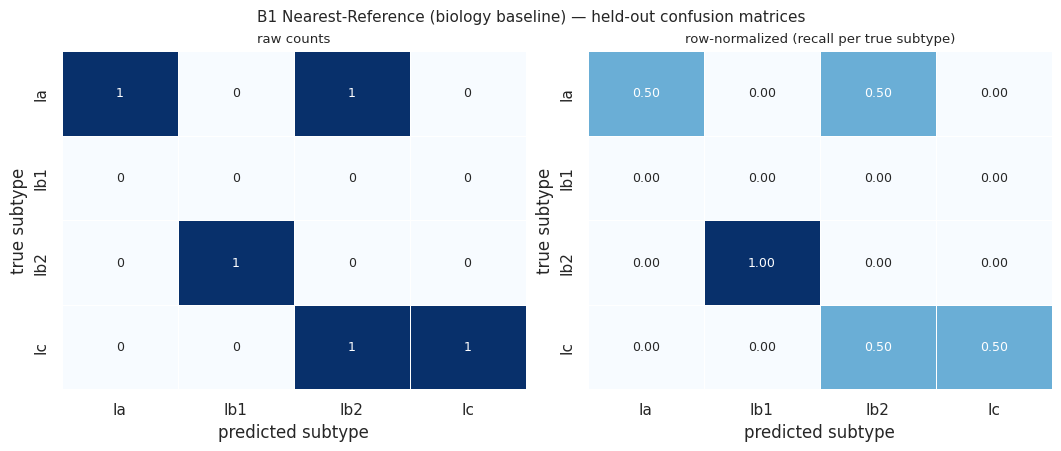

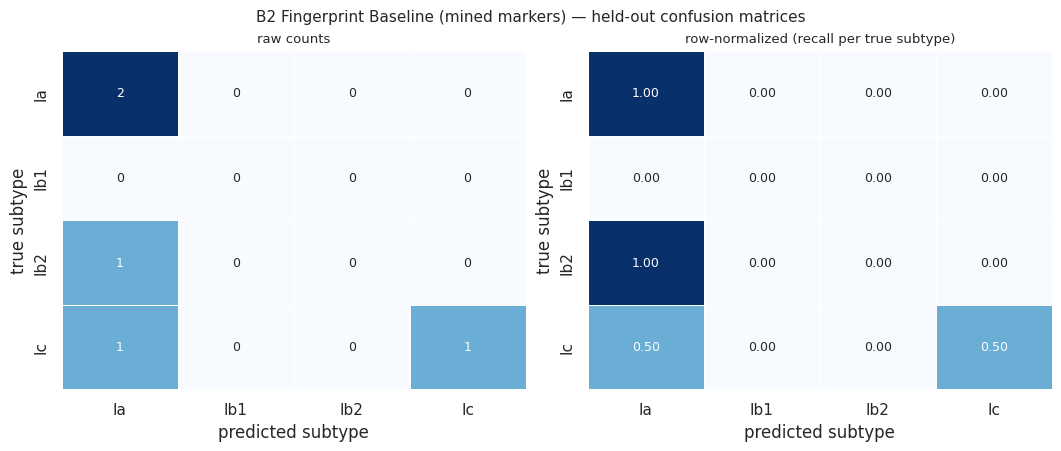

{'key': 'b2_fingerprint_baseline',
 'name': 'B2 Fingerprint Baseline (mined markers)',
 'tier': 'baseline',
 'feature_set': 'fp',
 'best_params': {},
 'n_candidates': 0,
 'cv_accuracy': 0.8421052631578947,
 'cv_bal_acc': 0.7083333333333334,
 'cv_macro_f1': 0.687799043062201,
 'cv_roc_auc': 0.9762250617030028,
 'cv_brier': 0.20622986036519872,
 'ho_accuracy': 0.6,
 'ho_bal_acc': 0.5,
 'ho_macro_f1': 0.4444444444444444,
 'ho_roc_auc': nan,
 'ho_brier': 0.5333549104437703,
 'fold_times': array([0.01724648, 0.0150423 , 0.01406837, 0.01492953, 0.01480126,
        0.01521134, 0.01496482, 0.01466322, 0.01408172, 0.01501799,
        0.01666427, 0.01488495, 0.01491094, 0.0148685 , 0.01443887,
        0.01457953, 0.01470971, 0.01481867, 0.01455188]),
 'rep': {'Ia': {'precision': 0.5,
   'recall': 1.0,
   'f1-score': 0.6666666666666666,
   'support': 2.0},
  'Ib1': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 0.0},
  'Ib2': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'supp

In [ ]:
class NearestReferenceClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, k=4, temperature=0.005):
        self.k = k; self.temperature = temperature

    def fit(self, X, y):
        seqs = [str(s).upper() for s in X['sequence']]
        y = np.asarray(y)
        self.classes_ = np.array(sorted(set(y.tolist())))
        self.keys_ = [''.join(p) for p in product('ACGT', repeat=self.k)]
        V = np.vstack([kmer_freq_vec(s, self.k, self.keys_) for s in seqs])
        nrm = np.linalg.norm(V, axis=1); nrm[nrm == 0] = 1.0
        self.refV_ = V / nrm[:, None]
        self.refy_ = y
        return self

    def _sims(self, X):
        seqs = [str(s).upper() for s in X['sequence']]
        Q = np.vstack([kmer_freq_vec(s, self.k, self.keys_) for s in seqs])
        nrm = np.linalg.norm(Q, axis=1); nrm[nrm == 0] = 1.0
        return (Q / nrm[:, None]) @ self.refV_.T

    def predict(self, X):
        return self.refy_[self._sims(X).argmax(axis=1)]

    def predict_proba(self, X):
        S = self._sims(X)
        P = np.zeros((S.shape[0], len(self.classes_)))
        for ci, c in enumerate(self.classes_):
            mask = self.refy_ == c
            P[:, ci] = S[:, mask].max(axis=1) if mask.any() else 0.0
        Z = P / self.temperature
        Z = Z - Z.max(axis=1, keepdims=True)
        E = np.exp(Z)
        return E / E.sum(axis=1, keepdims=True)

class MarkerProbaClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, alpha=0.1):
        self.alpha = alpha

    def fit(self, X, y):
        self.classes_ = np.array(sorted(set(np.asarray(y).tolist())))
        return self

    def predict_proba(self, X):
        M = np.asarray(X, dtype=float)
        Z = M + self.alpha
        return Z / Z.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

MODELS['b1_nearest_reference'] = dict(
    name='B1 Nearest-Reference (biology baseline)', tier='baseline',
    builder=lambda fs=None: Pipeline([('m', NearestReferenceClassifier(k=CHOSEN_K))]),
    grid=None, make_core=None)
MODELS['b2_fingerprint_baseline'] = dict(
    name='B2 Fingerprint Baseline (mined markers)', tier='baseline',
    builder=lambda fs=None: Pipeline([
        ('feat', SequenceFeatureTransformer(mode='fp', k=CHOSEN_K, marker_k=MARKER_K_CH,
                                            marker_x=MARKER_X_CH, marker_y=MARKER_Y_CH,
                                            marker_cap=MARKER_CAP, class_names=CLASSES)),
        ('clf', Pipeline([('m', MarkerProbaClassifier(alpha=0.1))]))]),
    grid=None, make_core=None)

evaluate_model('b1_nearest_reference', MODELS['b1_nearest_reference']['name'], 'baseline',
               MODELS['b1_nearest_reference']['builder'], grid=None)
evaluate_model('b2_fingerprint_baseline', MODELS['b2_fingerprint_baseline']['name'], 'baseline',
               MODELS['b2_fingerprint_baseline']['builder'], grid=None, feature_set='fp')

/home/z/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


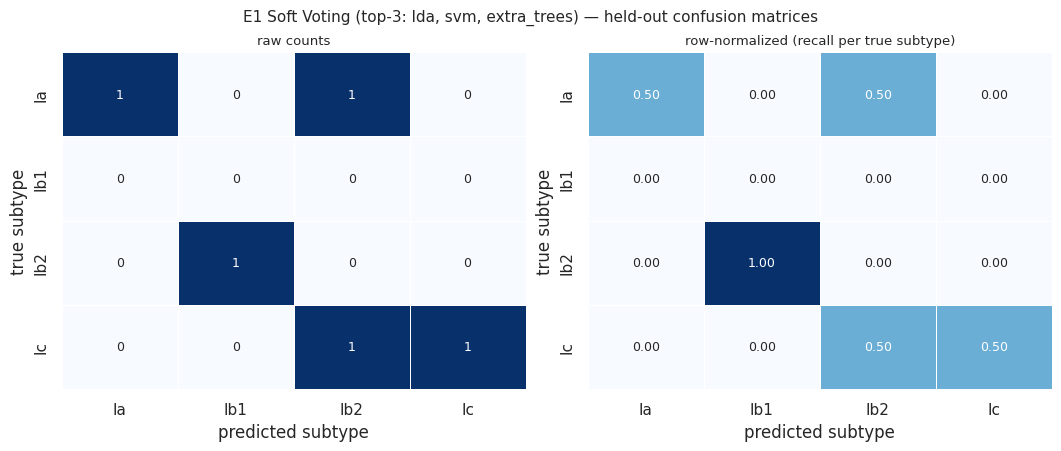

/home/z/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2480: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


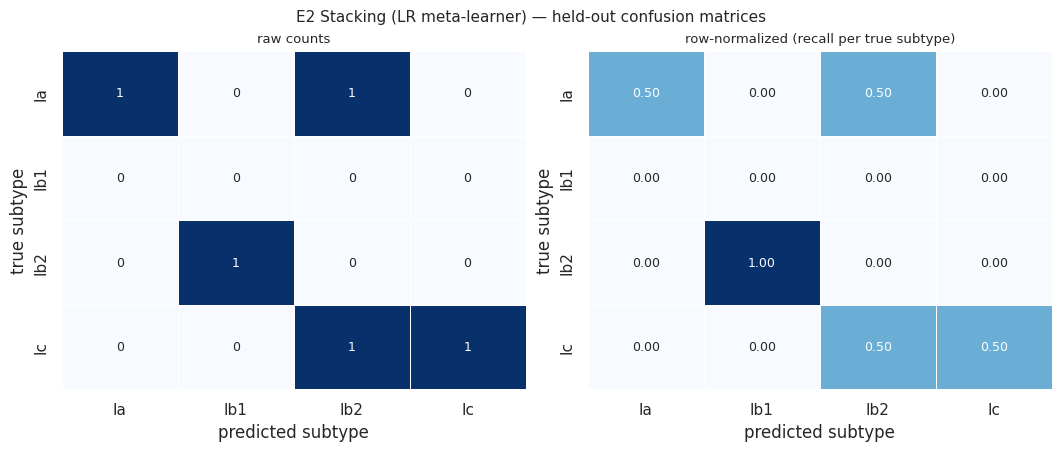

{'key': 'e2_stacking',
 'name': 'E2 Stacking (LR meta-learner)',
 'tier': 'ensemble',
 'feature_set': 'seq',
 'best_params': {},
 'n_candidates': 0,
 'cv_accuracy': nan,
 'cv_bal_acc': nan,
 'cv_macro_f1': nan,
 'cv_roc_auc': nan,
 'cv_brier': nan,
 'ho_accuracy': 0.4,
 'ho_bal_acc': 0.3333333333333333,
 'ho_macro_f1': 0.3333333333333333,
 'ho_roc_auc': nan,
 'ho_brier': 0.8136521362438774,
 'fold_times': array([0.78497076]),
 'rep': {'Ia': {'precision': 1.0,
   'recall': 0.5,
   'f1-score': 0.6666666666666666,
   'support': 2.0},
  'Ib1': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 0.0},
  'Ib2': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 1.0},
  'Ic': {'precision': 1.0,
   'recall': 0.5,
   'f1-score': 0.6666666666666666,
   'support': 2.0},
  'accuracy': 0.4,
  'macro avg': {'precision': 0.5,
   'recall': 0.25,
   'f1-score': 0.3333333333333333,
   'support': 5.0},
  'weighted avg': {'precision': 0.8,
   'recall': 0.4,
   'f1-score': 0.5333333333

In [23]:
ENS_EXCLUDE = {'b1_nearest_reference', 'b2_fingerprint_baseline', 'e1_voting', 'e2_stacking', 'multinomial_nb'}
cands = [(k, RESULTS[k]['cv_bal_acc']) for k in RESULTS
         if k not in ENS_EXCLUDE and not np.isnan(RESULTS[k]['cv_bal_acc'])]
top3 = sorted(cands, key=lambda kv: (-kv[1], kv[0]))[:3]

def _base_estimators():
    out = []
    for k, _ in top3:
        core = MODELS[k]['make_core'](RESULTS[k]['best_params'])
        out.append((k, Pipeline([('scale', StandardScaler()), ('m', core)])))
    return out

stack_cv = int(min(5, int(pd.Series(Y_TRAIN).value_counts().min())))
MODELS['e1_voting'] = dict(
    name=f'E1 Soft Voting (top-3: {", ".join(k for k, _ in top3)})', tier='ensemble',
    builder=lambda fs=None: Pipeline([('feat', build_transformer(FINAL_FEATURESET)),
                                      ('clf', VotingClassifier(estimators=_base_estimators(), voting='soft'))]),
    grid=None, make_core=None)
MODELS['e2_stacking'] = dict(
    name='E2 Stacking (LR meta-learner)', tier='ensemble',
    builder=lambda fs=None: Pipeline([('feat', build_transformer(FINAL_FEATURESET)),
                                      ('clf', StackingClassifier(estimators=_base_estimators(),
                                                                 final_estimator=LogisticRegression(
                                                                     max_iter=2000, random_state=RANDOM_STATE),
                                                                 cv=stack_cv, stack_method='predict_proba'))]),
    grid=None, make_core=None)

evaluate_model('e1_voting', MODELS['e1_voting']['name'], 'ensemble', MODELS['e1_voting']['builder'], grid=None)
evaluate_model('e2_stacking', MODELS['e2_stacking']['name'], 'ensemble', MODELS['e2_stacking']['builder'],
               grid=None, oof_enabled=False)

In [24]:
comp_rows = []
for key, r in RESULTS.items():
    comp_rows.append({
        'key': key, 'model': r['name'], 'tier': r['tier'], 'feature_set': r['feature_set'],
        'best_params': str(r['best_params']) if r['best_params'] else '(none)',
        'cv_accuracy': r['cv_accuracy'], 'cv_balanced_accuracy': r['cv_bal_acc'],
        'cv_macro_f1': r['cv_macro_f1'], 'cv_roc_auc_ovr': r['cv_roc_auc'], 'cv_brier': r['cv_brier'],
        'heldout_accuracy': r['ho_accuracy'], 'heldout_balanced_accuracy': r['ho_bal_acc'],
        'heldout_macro_f1': r['ho_macro_f1'], 'heldout_roc_auc_ovr': r['ho_roc_auc'],
        'heldout_brier': r['ho_brier'],
        'fit_time_mean_s': r['fold_times'].mean() if len(r['fold_times']) else np.nan,
        'cv_folds_fit_time_s': float(np.mean(r['fold_times'])) if r['fold_times'].size else np.nan,
    })
COMP_DF = pd.DataFrame(comp_rows)
COMP_DF.to_csv(os.path.join(OUTDIR, 'model_comparison.csv'), index=False)
pd.DataFrame(CM_ROWS).to_csv(os.path.join(OUTDIR, 'per_model_confusion_matrices.csv'), index=False)
print('[model_comparison.csv] and [per_model_confusion_matrices.csv] written.')

def _rank_tuple(key):
    r = RESULTS[key]
    cvb = r['cv_bal_acc'] if not np.isnan(r['cv_bal_acc']) else -1.0
    hob = r['ho_bal_acc'] if not np.isnan(r['ho_bal_acc']) else -1.0
    f1 = r['cv_macro_f1'] if not np.isnan(r['cv_macro_f1']) else -1.0
    pri = 0 if key == 'svm' else 1
    return (-cvb, -hob, -f1, pri, key)

ranked = sorted(RESULTS.keys(), key=_rank_tuple)
best_key, runner_key = ranked[0], ranked[1]
margin = (RESULTS[best_key]['cv_bal_acc'] - RESULTS[runner_key]['cv_bal_acc']
          if not np.isnan(RESULTS[best_key]['cv_bal_acc']) and not np.isnan(RESULTS[runner_key]['cv_bal_acc'])
          else np.nan)
lb = COMP_DF.sort_values('cv_balanced_accuracy', ascending=False, na_position='last')
display(lb[['model', 'tier', 'cv_balanced_accuracy', 'heldout_balanced_accuracy', 'cv_macro_f1', 'heldout_macro_f1', 'cv_roc_auc_ovr', 'cv_brier', 'fit_time_mean_s']].round(3))
b1_ok = RESULTS[best_key]['cv_bal_acc'] > RESULTS['b1_nearest_reference']['cv_bal_acc']
b2_ok = RESULTS[best_key]['cv_bal_acc'] > RESULTS['b2_fingerprint_baseline']['cv_bal_acc']

[model_comparison.csv] and [per_model_confusion_matrices.csv] written.


,model,tier,cv_balanced_accuracy,heldout_balanced_accuracy,cv_macro_f1,heldout_macro_f1,cv_roc_auc_ovr,cv_brier,fit_time_mean_s
12,"E1 Soft Voting (top-3: lda, svm, extra_trees)",ensemble,0.896,0.333,0.844,0.333,0.982,0.262,0.140
9,Linear Discriminant Analysis,benchmark,0.896,0.333,0.844,0.333,0.926,0.316,0.019
0,"SVM (calibrated, primary)",primary,0.875,0.333,0.899,0.167,0.877,0.479,0.030
2,Random Forest,benchmark,0.854,0.333,0.819,0.333,0.944,0.343,0.131
3,Extra Trees,benchmark,0.854,0.333,0.819,0.333,0.944,0.303,0.099
10,B1 Nearest-Reference (biology baseline),baseline,0.854,0.333,0.804,0.333,0.929,0.487,0.003
5,KNN (cosine),benchmark,0.844,0.167,0.833,0.125,0.908,0.316,0.012
8,MLP (small-sample caveat),benchmark,0.823,0.167,0.776,0.167,0.837,0.423,0.048
1,Logistic Regression (multinomial),benchmark,0.781,0.333,0.730,0.292,0.882,0.450,0.013
4,Gradient Boosting (LightGBM backend),benchmark,0.729,0.167,0.610,0.125,0.851,0.680,0.035


## STEP 7 — Figures (all `.png`, dpi 300, saved before display)

Each figure answers one question: **fig3** — does the engineered feature space separate the four subtypes, where did the 22 user-labeled partials land inside their assigned subtype clouds, and where do the 10 to-classify targets land (projected, never fitted)? **fig5** — how large are the per-subtype one-vs-rest ROC areas under the protocol's fold-safe out-of-fold predictions? **fig6** — which subtypes are hard *for which model* (per-class F1 on the hold-out)? **fig7** — the head-to-head comparison with 95% bootstrap CIs (1,000 resamples of the OOF samples; fit-time CIs bootstrap the per-fold fit times). **fig8** — do the top-3 models' probabilities *mean what they say* (reliability diagrams + Brier)? **fig9** — which features carry the winner's decisions, and where do fingerprint features rank? Small-sample caveats are printed with each figure: the hold-out contains only a handful of the ~40 original rows, so CV/OOF quantities are the primary evidence and held-out numbers are shown for protocol completeness.


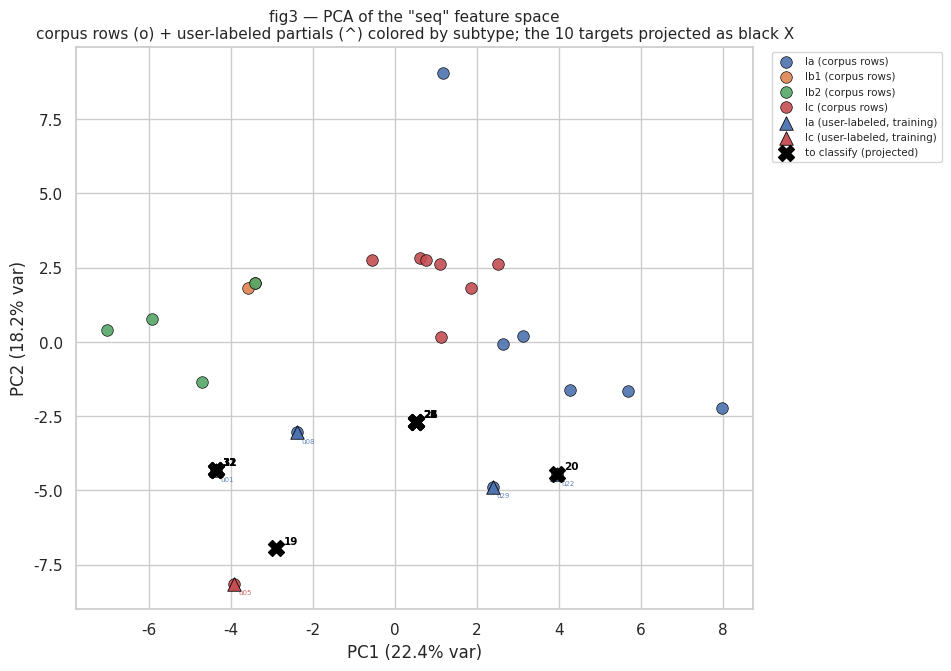

In [25]:
X_NEW_DF = pd.DataFrame({'sequence': TO_CLASSIFY_DF['sequence'].values},
                        index=TO_CLASSIFY_DF['seq_id'].astype(str).values)

feat_full = build_transformer(FINAL_FEATURESET).fit(X_ORIG_DF, Y_ORIG)
Xall_t = feat_full.transform(X_ORIG_DF)
scaler_pca = StandardScaler().fit(Xall_t)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(scaler_pca.transform(Xall_t))
Z_ref = pca.transform(scaler_pca.transform(Xall_t))
Z_new = pca.transform(scaler_pca.transform(feat_full.transform(X_NEW_DF)))
X_user_DF = pd.DataFrame({'sequence': USER_LAB_DF['sequence'].values},
                         index=USER_LAB_DF['corpus_id'].values)
Z_user = pca.transform(scaler_pca.transform(feat_full.transform(X_user_DF)))

palette = dict(zip(CLASSES, ['#4C72B0', '#DD8452', '#55A868', '#C44E52']))
fig, ax = plt.subplots(figsize=(9.4, 6.6), constrained_layout=True)
for c, st in enumerate(CLASSES):
    m = Y_ORIG == c
    ax.scatter(Z_ref[m, 0], Z_ref[m, 1], s=70, color=palette[st], edgecolor='black',
               linewidth=0.5, label=f'{st} (corpus rows)', zorder=3, alpha=0.9)
for c, st in enumerate(CLASSES):
    mu = (USER_LAB_DF['subtype'] == st).values
    if mu.any():
        ax.scatter(Z_user[mu, 0], Z_user[mu, 1], s=95, marker='^', color=palette[st],
                   edgecolor='black', linewidth=0.6, label=f'{st} (user-labeled, training)', zorder=4, alpha=0.95)
ax.scatter(Z_new[:, 0], Z_new[:, 1], marker='X', s=130, color='black', label='to classify (projected)',
           zorder=5)
for i, sid in enumerate(X_NEW_DF.index):
    ax.annotate(sid, (Z_new[i, 0], Z_new[i, 1]), textcoords='offset points', xytext=(5, 3),
                fontsize=7.5, color='black', fontweight='bold')
for i, sid in enumerate(X_user_DF.index):
    ax.annotate(sid, (Z_user[i, 0], Z_user[i, 1]), textcoords='offset points', xytext=(3, -8),
                fontsize=5, color=palette[USER_LAB_DF['subtype'].iloc[i]], alpha=0.85)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)')
ax.set_title(f'fig3 — PCA of the "{FINAL_FEATURESET}" feature space\n'
             'corpus rows (o) + user-labeled partials (^) colored by subtype; the 10 targets projected as black X',
             fontsize=11)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=7.5, frameon=True)
save_and_show('fig3_pca_feature_space.png', fig)

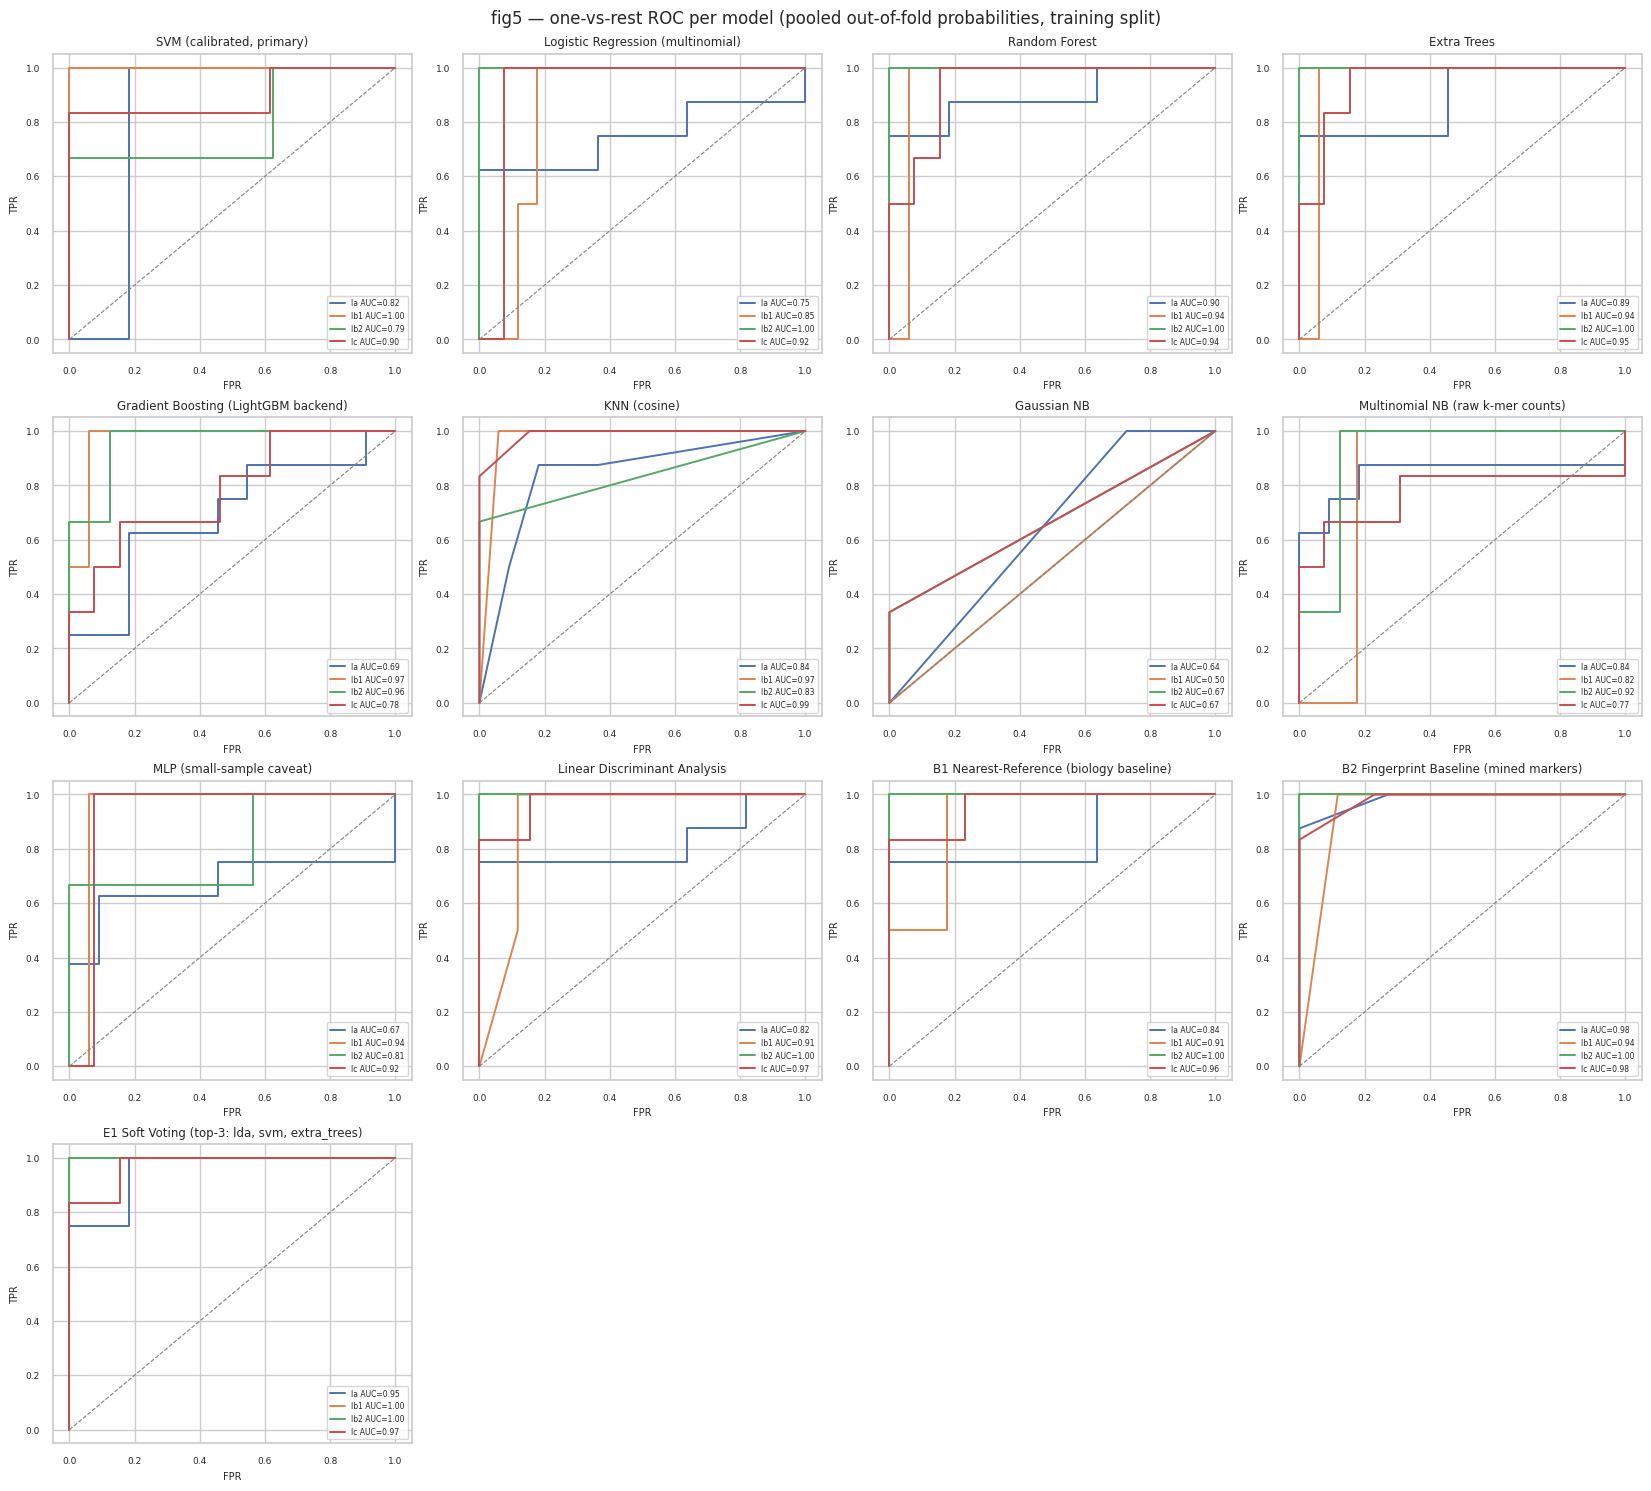

In [26]:
roc_keys = [k for k, v in OOF_STORE.items() if v is not None]
roc_keys = ['svm'] + [k for k in roc_keys if k != 'svm']
n = len(roc_keys)
ncol = 4
nrow = int(np.ceil(n / ncol))
Yb_tr = label_binarize(Y_TRAIN, classes=list(range(len(CLASSES))))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.1 * ncol, 3.7 * nrow), constrained_layout=True)
axes = np.atleast_2d(axes)
for idx, key in enumerate(roc_keys):
    ax = axes[idx // ncol, idx % ncol]
    y_o, P_o = OOF_STORE[key]
    yb = label_binarize(y_o, classes=list(range(len(CLASSES))))
    for c, st in enumerate(CLASSES):
        try:
            fpr, tpr, _ = roc_curve(yb[:, c], P_o[:, c])
            auc_c = roc_auc_score(yb[:, c], P_o[:, c])
            ax.plot(fpr, tpr, lw=1.4, color=palette[st], label=f'{st} AUC={auc_c:.2f}')
        except Exception:
            pass
    ax.plot([0, 1], [0, 1], ls='--', color='gray', lw=0.8)
    ax.set_title(RESULTS[key]['name'], fontsize=8.5)
    ax.set_xlabel('FPR', fontsize=7); ax.set_ylabel('TPR', fontsize=7)
    ax.tick_params(labelsize=6.5)
    ax.legend(fontsize=5.5, loc='lower right')
for idx in range(n, nrow * ncol):
    axes[idx // ncol, idx % ncol].axis('off')
fig.suptitle('fig5 — one-vs-rest ROC per model (pooled out-of-fold probabilities, training split)',
             fontsize=12)
save_and_show('fig5_roc_per_model.png', fig)

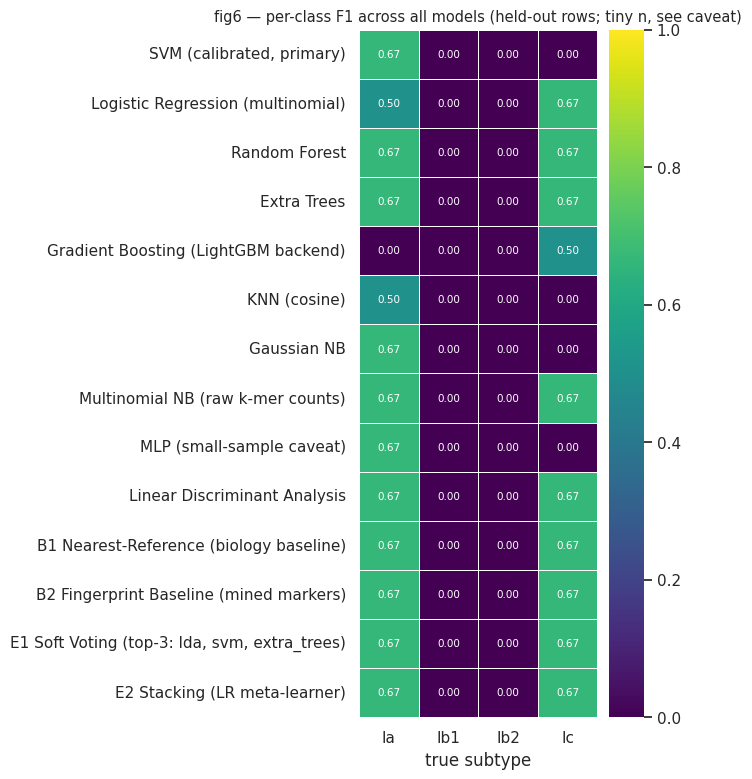

In [27]:
f1_mat = np.zeros((len(RESULTS), len(CLASSES)))
keys_ord = list(RESULTS.keys())
for i, k in enumerate(keys_ord):
    for j, st in enumerate(CLASSES):
        f1_mat[i, j] = RESULTS[k]['rep'][st]['f1-score']
fig, ax = plt.subplots(figsize=(6.8, 0.42 * len(keys_ord) + 1.8), constrained_layout=True)
if HAS_SNS:
    sns.heatmap(f1_mat, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1, cbar=True,
                xticklabels=CLASSES, yticklabels=[RESULTS[k]['name'] for k in keys_ord],
                ax=ax, annot_kws={'fontsize': 7.5}, linewidths=0.4, linecolor='white')
else:
    im = ax.imshow(f1_mat, cmap='viridis', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(len(keys_ord))); ax.set_yticklabels([RESULTS[k]['name'] for k in keys_ord], fontsize=7)
    for i in range(f1_mat.shape[0]):
        for j in range(f1_mat.shape[1]):
            ax.text(j, i, f'{f1_mat[i, j]:.2f}', ha='center', va='center', fontsize=7,
                    color='white' if f1_mat[i, j] < 0.6 else 'black')
ax.set_title('fig6 — per-class F1 across all models (held-out rows; tiny n, see caveat)', fontsize=10.5)
ax.set_xlabel('true subtype')
save_and_show('fig6_per_class_f1.png', fig)

In [ ]:
metric_fns = {
    'CV accuracy': lambda y, P: accuracy_score(y, P.argmax(axis=1)),
    'CV balanced accuracy': lambda y, P: balanced_accuracy_score(y, P.argmax(axis=1)),
    'CV macro-F1': lambda y, P: f1_score(y, P.argmax(axis=1), average='macro', zero_division=0),
}
order = sorted(RESULTS.keys(), key=lambda k: (-(RESULTS[k]['cv_bal_acc'] if not np.isnan(RESULTS[k]['cv_bal_acc']) else -1), k))
tier_color = {'primary': '#C44E52', 'benchmark': '#4C72B0', 'baseline': '#55A868', 'ensemble': '#8172B2'}

def boot_ci(vals, n_boot=N_BOOT, seed=RANDOM_STATE):
    vals = np.asarray(vals, float)
    rng = np.random.default_rng(seed)
    means = [float(np.mean(vals[rng.integers(0, len(vals), len(vals))])) for _ in range(n_boot)]
    return np.percentile(means, [2.5, 97.5])

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.2), constrained_layout=True)
panels = ['CV accuracy', 'CV balanced accuracy', 'CV macro-F1']
ypos = np.arange(len(order))
for pi, panel in enumerate(panels + ['Mean fit time per CV fold (s)']):
    ax = axes[pi // 2, pi % 2]
    xs, errs_lo, errs_hi, cols, labels = [], [], [], [], []
    for i, k in enumerate(order):
        r = RESULTS[k]
        if panel.startswith('CV ') and OOF_STORE.get(k) is not None:
            fn = metric_fns[panel]
            vals = []
            y_o, P_o = OOF_STORE[k]
            rng = np.random.default_rng(RANDOM_STATE + i)
            nn = len(y_o)
            for _ in range(N_BOOT):
                ii = rng.integers(0, nn, nn)
                vals.append(fn(y_o[ii], P_o[ii]))
            vals = np.asarray(vals, float)
            ctr = float(np.nanmean(vals))
            lo, hi = np.nanpercentile(vals, [2.5, 97.5])
            errs_lo.append(max(0.0, ctr - lo)); errs_hi.append(max(0.0, hi - ctr))
            xs.append(ctr)
        elif panel.startswith('Mean fit'):
            ft = r['fold_times']
            ctr = float(np.mean(ft))
            lo, hi = boot_ci(ft)
            errs_lo.append(max(0.0, ctr - lo)); errs_hi.append(max(0.0, hi - ctr))
            xs.append(ctr)
        else:
            xs.append(np.nan); errs_lo.append(0); errs_hi.append(0)
        cols.append(tier_color.get(r['tier'], 'gray'))
        labels.append(r['name'])
    bp = ax.barh(ypos, xs, xerr=[errs_lo, errs_hi], color=cols, edgecolor='black',
                 linewidth=0.5, capsize=2.5, error_kw={'lw': 0.9})
    ax.set_yticks(ypos); ax.set_yticklabels(labels, fontsize=7)
    ax.invert_yaxis()
    ax.set_title(panel + ('  (95% bootstrap CI)' if panel != 'Mean fit time per CV fold (s)' else '  (95% bootstrap CI over fold times)'), fontsize=10)
    for lbl in ax.get_xticklabels():
        lbl.set_fontsize(7.5)
from matplotlib.patches import Patch
handles = [Patch(color=tier_color[t], label=t) for t in ['primary', 'benchmark', 'baseline', 'ensemble']]
axes[0, 0].legend(handles=handles, fontsize=7, loc='lower right')
fig.suptitle('fig7 — model comparison with 95% bootstrap CIs (1,000 resamples of OOF samples / fold times)',
             fontsize=12)
save_and_show('fig7_model_comparison.png', fig)

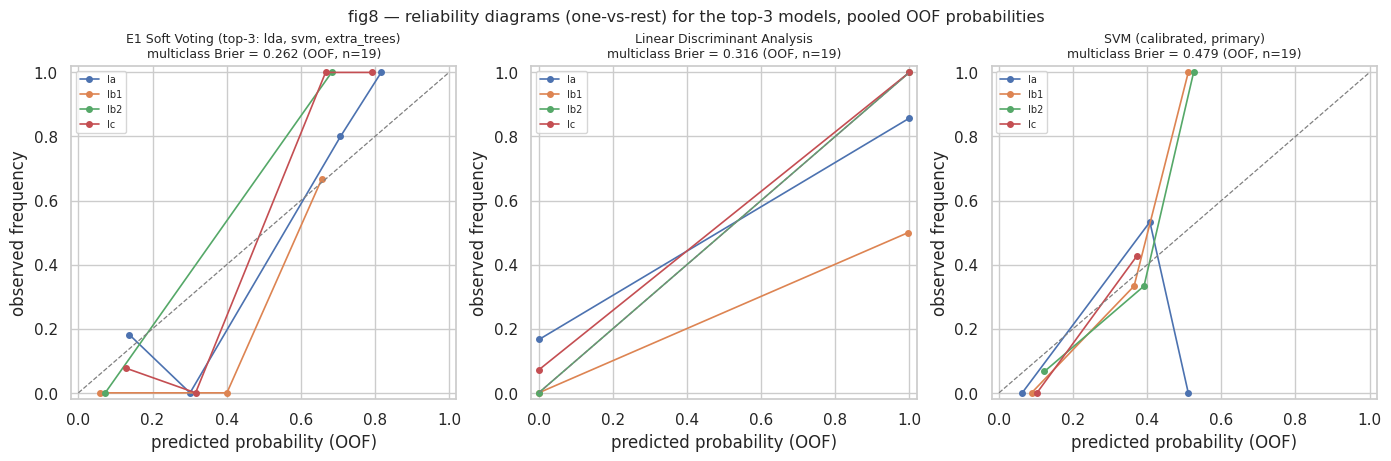

In [29]:
top3_cal = [k for k in sorted(RESULTS.keys(), key=_rank_tuple)
            if OOF_STORE.get(k) is not None][:3]
fig, axes = plt.subplots(1, len(top3_cal), figsize=(4.6 * len(top3_cal), 4.5), constrained_layout=True,
                         squeeze=False)
for ax, key in zip(axes[0], top3_cal):
    y_o, P_o = OOF_STORE[key]
    yb = label_binarize(y_o, classes=list(range(len(CLASSES))))
    for c, st in enumerate(CLASSES):
        try:
            frac_pos, mean_pred = calibration_curve(yb[:, c], P_o[:, c], n_bins=4, strategy='uniform')
            ax.plot(mean_pred, frac_pos, marker='o', ms=4, lw=1.2, color=palette[st], label=st)
        except Exception:
            pass
    ax.plot([0, 1], [0, 1], ls='--', color='gray', lw=0.9)
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel('predicted probability (OOF)')
    ax.set_ylabel('observed frequency')
    ax.set_title(f'{RESULTS[key]["name"]}\nmulticlass Brier = {RESULTS[key]["cv_brier"]:.3f} (OOF, n={len(y_o)})',
                 fontsize=9)
    ax.legend(fontsize=7, loc='upper left')
fig.suptitle('fig8 — reliability diagrams (one-vs-rest) for the top-3 models, pooled OOF probabilities',
             fontsize=11.5)
save_and_show('fig8_calibration_top3.png', fig)

In [ ]:
best_est = RESULTS[best_key]['best_est']
if 'feat' in best_est.named_steps:
    feat_perm = clone(best_est.named_steps['feat']).fit(X_TRAIN_DF, Y_TRAIN)
    Xtr_t = feat_perm.transform(X_TRAIN_DF)
    Xte_t = feat_perm.transform(X_TEST_DF)
    rest_core = clone(best_est.named_steps['clf'])
else:

    class _B1Adapter(BaseEstimator, ClassifierMixin):
        def fit(self, X, y):
            self.classes_ = np.array(sorted(set(np.asarray(y).tolist())))
            V = np.asarray(X, dtype=float)
            nrm = np.linalg.norm(V, axis=1); nrm[nrm == 0] = 1.0
            self.V_ = V / nrm[:, None]
            self.y_ = np.asarray(y)
            return self
        def predict(self, X):
            Q = np.asarray(X, dtype=float)
            nrm = np.linalg.norm(Q, axis=1); nrm[nrm == 0] = 1.0
            S = (Q / nrm[:, None]) @ self.V_.T
            return self.y_[S.argmax(axis=1)]
        def predict_proba(self, X):
            Q = np.asarray(X, dtype=float)
            nrm = np.linalg.norm(Q, axis=1); nrm[nrm == 0] = 1.0
            S = (Q / nrm[:, None]) @ self.V_.T
            P = np.zeros((S.shape[0], len(self.classes_)))
            for ci, c in enumerate(self.classes_):
                mask = self.y_ == c
                P[:, ci] = S[:, mask].max(axis=1) if mask.any() else 0.0
            Z = P / 0.005
            Z = Z - Z.max(axis=1, keepdims=True)
            E = np.exp(Z)
            return E / E.sum(axis=1, keepdims=True)
    feat_perm = build_transformer('seq').fit(X_TRAIN_DF, Y_TRAIN)
    Xtr_t = feat_perm.transform(X_TRAIN_DF)
    Xte_t = feat_perm.transform(X_TEST_DF)
    rest_core = _B1Adapter()
keep_cols = Xtr_t.columns[Xtr_t.var() > 1e-12]
Xtr_t2, Xte_t2 = Xtr_t[keep_cols], Xte_t[keep_cols]
rest = rest_core.fit(Xtr_t2, Y_TRAIN)
pi = permutation_importance(rest, Xte_t2, Y_TEST, n_repeats=N_PERM_REPEATS,
                            random_state=RANDOM_STATE, scoring='balanced_accuracy', n_jobs=1)
PERM_DF = pd.DataFrame({'feature': list(keep_cols),
                        'importance_mean': pi.importances_mean,
                        'importance_std': pi.importances_std}).sort_values('importance_mean', ascending=False)
PERM_DF['is_fingerprint'] = PERM_DF['feature'].str.startswith('fpmined_')
PERM_DF.to_csv(os.path.join(OUTDIR, 'permutation_importance.csv'), index=False)

fp_rows = PERM_DF[PERM_DF['is_fingerprint']]
topn = min(20, len(PERM_DF))
plot_df = PERM_DF.head(topn).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.32 * topn + 2.2), constrained_layout=True)
colors = ['#C44E52' if f else '#7A7A7A' for f in plot_df['is_fingerprint']]
ax.barh(range(len(plot_df)), plot_df['importance_mean'], xerr=plot_df['importance_std'],
        color=colors, edgecolor='black', linewidth=0.4, capsize=2)
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df['feature'], fontsize=7)
ax.set_xlabel('permutation importance (mean drop in balanced accuracy +/- std)')
ax.set_title(f'fig9 — permutation importance, top {topn} features of {RESULTS[best_key]["name"]}\n'
             '(red = mined fingerprint feature; hold-out n=' + str(len(Y_TEST)) + ' — noisy, interpret ranks only)',
             fontsize=10)
save_and_show('fig9_permutation_importance.png', fig)
if len(fp_rows):
    best_fp = fp_rows.iloc[0]
    rank = int(PERM_DF.index.get_loc(fp_rows.index[0])) + 1

## STEP 8 — Final Predictions on the 10 Remaining Unlabeled Partials (mandatory)

**Procedure.** The **winning pipeline and both ensembles are re-fitted on ALL training data** — the full combined corpus, fold-safe balance-augmented so every subtype trains at the "highest value" count (the other models keep their training-split fits, disclosed per row via the `refit_on_all_data` column) — after which every model predicts the **10 remaining unlabeled partials** (12, 19, 20, 21, 23, 24, 25, 26, 31, 32). For **every** model the output carries the identical columns `SeqID | P(Subtype) x4 | Predicted | Confidence(max P) | Margin(top1-top2) | Normalized entropy`, exported to `new_sequence_predictions.csv` (long: target x model) with a wide table for the final model. The **low-confidence flag** fires when `max P < 0.6` OR `margin < 0.15` OR `normalized entropy > 0.9` (entropy normalized by `ln 4` so 1.0 = uniform). `fingerprint_scores_for_new32.csv` contains the **mined-marker digital fingerprints of all 32 partials** annotated `user_labeled_train` vs `to_classify` (never fabricated CSV scores — method and validation statistics disclosed in Step 3b), and the fingerprint baseline's **conflict** (top-2 within 0.1) and **no-signal** (all-zero profile) flags are reported alongside its votes. A dedicated **user-label consistency check** (Step 8b) validates the 22 user-provided training labels with fold-safe LOOCV: each user row is predicted by a model that never saw it — nor any synthetic copy of it.


In [31]:
SENS = {'n_flagged': 0, 'cv_bal_acc_all': np.nan, 'cv_bal_acc_clean': np.nan, 'n_changed_predictions': np.nan,
        'note': 'not applicable'}
if SCHEMA == 'B' and len(FLAGGED_DF):
    flagged_ids = set(FLAGGED_DF['ref_id'])
    keep_mask = ~ORIG_META['corpus_id'].isin(flagged_ids).values
    keep_pos = np.where(keep_mask)[0]
    X_clean_orig, Y_clean_orig = X_ORIG_DF.iloc[keep_pos], Y_ORIG[keep_pos]
    SENS['n_flagged'] = int((~keep_mask).sum())
    counts_clean = Counter(Y_clean_orig.tolist())
    missing_subtypes = [CLASSES[c] for c in range(len(CLASSES)) if counts_clean.get(c, 0) == 0]

    def _sens_cv(Xd, yd):

        mc = int(pd.Series(yd).value_counts().min())
        if mc < 2:
            return np.nan, 'CV impossible (a subtype would have <2 rows)'
        Xa, ya, cpy, n_o = make_balanced_augment(Xd, yd, seed=RANDOM_STATE)
        sp = splits_balanced(n_o, cpy, mode='stratified', y_orig=yd, n_splits=int(min(5, mc)), seed=RANDOM_STATE)
        P_full, _t = oof_predict_proba(clone(RESULTS[best_key]['best_est']), Xa, ya, sp, np.arange(len(CLASSES)))
        return float(balanced_accuracy_score(yd, P_full[:n_o].argmax(axis=1))), \
               f'fold-safe StratifiedKFold({int(min(5, mc))}) OOF on original rows'

    SENS['cv_bal_acc_all'], note_all = _sens_cv(X_ORIG_DF, Y_ORIG)
    if missing_subtypes:

        SENS['cv_bal_acc_clean'] = np.nan
        SENS['n_changed_predictions'] = np.nan
        SENS['note'] = (f'full corpus CV: {note_all}; flagged-removed corpus: subtype(s) '
                        f'{", ".join(missing_subtypes)} eliminated entirely -> CV and refit not meaningful, '
                        f'only the retained-corpus CV is reported')
    else:
        SENS['cv_bal_acc_clean'], note_clean = _sens_cv(X_clean_orig, Y_clean_orig)
        Xa_all, ya_all, _, _ = make_balanced_augment(X_ORIG_DF, Y_ORIG, seed=RANDOM_STATE)
        refit_all = clone(RESULTS[best_key]['best_est']).fit(Xa_all, ya_all)
        Xa_cl, ya_cl, _, _ = make_balanced_augment(X_clean_orig, Y_clean_orig, seed=RANDOM_STATE)
        refit_clean = clone(RESULTS[best_key]['best_est']).fit(Xa_cl, ya_cl)
        p_all = refit_all.predict(X_NEW_DF)
        p_clean = refit_clean.predict(X_NEW_DF)
        SENS['n_changed_predictions'] = int((p_all != p_clean).sum())
        SENS['note'] = f'full corpus CV: {note_all}; flagged-removed corpus CV: {note_clean}'

In [ ]:
def predict_new_sequences(est, X_new):
    P = est.predict_proba(X_new)
    pred = P.argmax(axis=1)
    conf = P.max(axis=1)
    srt = np.sort(P, axis=1)
    margin = srt[:, -1] - srt[:, -2]
    H = -(P * np.log(np.clip(P, 1e-12, None))).sum(axis=1) / np.log(len(CLASSES))
    low = (conf < LOW_CONF_MAXP) | (margin < LOW_CONF_MARGIN) | (H > LOW_CONF_ENTROPY)
    out = pd.DataFrame({'predicted': [CLASSES[p] for p in pred], 'confidence': conf,
                        'margin': margin, 'norm_entropy': H, 'low_confidence': low})
    for j, st in enumerate(CLASSES):
        out[f'P_{st}'] = P[:, j]
    return out[['predicted'] + [f'P_{st}' for st in CLASSES] +
               ['confidence', 'margin', 'norm_entropy', 'low_confidence']]

X_FITAUG_DF, Y_FITAUG, FIT_COPY_OF, _ = make_balanced_augment(X_ORIG_DF, Y_ORIG, seed=RANDOM_STATE)
REFIT_KEYS = sorted({best_key, 'e1_voting', 'e2_stacking'} & set(RESULTS.keys()))
REFIT = {k: clone(FITTED[k]).fit(X_FITAUG_DF, Y_FITAUG) for k in REFIT_KEYS}

long_rows = []
for key in RESULTS.keys():
    est = REFIT.get(key, FITTED[key])
    tab = predict_new_sequences(est, X_NEW_DF)
    tab.insert(0, 'seq_id', [str(v) for v in X_NEW_DF.index])
    tab.insert(1, 'model', key)
    tab.insert(2, 'model_name', RESULTS[key]['name'])
    tab.insert(3, 'refit_on_all_data', key in REFIT_KEYS)
    long_rows.append(tab)
PRED_LONG = pd.concat(long_rows, ignore_index=True)

b2_scores_new = FITTED['b2_fingerprint_baseline'].named_steps['feat'].transform(X_NEW_DF)
b2_vals = b2_scores_new.values
top2 = np.sort(b2_vals, axis=1)
b2_conflict = (top2[:, -1] - top2[:, -2]) < 0.1
b2_nosignal = b2_vals.max(axis=1) == 0
b2_mask = PRED_LONG['model'] == 'b2_fingerprint_baseline'
PRED_LONG['b2_top2_conflict(<0.1)'] = np.nan
PRED_LONG['b2_no_signal'] = np.nan
PRED_LONG.loc[b2_mask, 'b2_top2_conflict(<0.1)'] = np.tile(b2_conflict, b2_mask.sum() // len(b2_conflict)) if b2_mask.sum() else np.nan
PRED_LONG.loc[b2_mask, 'b2_no_signal'] = np.tile(b2_nosignal, b2_mask.sum() // len(b2_nosignal)) if b2_mask.sum() else np.nan

PRED_LONG.to_csv(os.path.join(OUTDIR, 'new_sequence_predictions.csv'), index=False)
PRED_WIDE = PRED_LONG[PRED_LONG['model'] == best_key].drop(columns=['model', 'model_name', 'refit_on_all_data',
                                                                    'b2_top2_conflict(<0.1)', 'b2_no_signal'])
PRED_WIDE.to_csv(os.path.join(OUTDIR, 'new_sequence_predictions_wide_final_model.csv'), index=False)
NEW_PROFILES.to_csv(os.path.join(OUTDIR, 'fingerprint_scores_for_new32.csv'), index=False)
display(PRED_WIDE.round(3))

dist = PRED_WIDE['predicted'].value_counts()
n_low = int(PRED_WIDE['low_confidence'].sum())
pred_mat = PRED_LONG.pivot_table(index='seq_id', columns='model', values='predicted',
                                 aggfunc=lambda s: s.iloc[0])
n_disagree = int((pred_mat.nunique(axis=1) > 1).sum())
final_pred = PRED_WIDE.set_index('seq_id')['predicted']
b2_pred = PRED_LONG[b2_mask].set_index('seq_id')['predicted']
b2_dis = [sid for sid in final_pred.index if b2_pred.get(sid) != final_pred[sid]]

[new_sequence_predictions.csv] (long: target x model) written.
[new_sequence_predictions_wide_final_model.csv] written (final model, 10 targets).
[fingerprint_scores_for_new32.csv] written (mined-marker digital fingerprints of ALL 32 partials,


,seq_id,predicted,P_Ia,P_Ib1,P_Ib2,P_Ic,confidence,margin,norm_entropy,low_confidence
120,12,Ia,0.829,0.017,0.108,0.045,0.829,0.721,0.437,False
121,19,Ic,0.253,0.018,0.054,0.675,0.675,0.422,0.608,False
122,20,Ia,0.837,0.032,0.027,0.104,0.837,0.733,0.426,False
123,21,Ia,0.800,0.042,0.029,0.128,0.800,0.673,0.490,False
124,23,Ia,0.800,0.042,0.029,0.128,0.800,0.673,0.490,False
125,24,Ia,0.800,0.042,0.029,0.128,0.800,0.673,0.490,False
126,25,Ia,0.800,0.042,0.029,0.128,0.800,0.673,0.490,False
127,26,Ia,0.800,0.042,0.029,0.128,0.800,0.673,0.490,False
128,31,Ia,0.829,0.017,0.108,0.045,0.829,0.721,0.437,False
129,32,Ia,0.829,0.017,0.108,0.045,0.829,0.721,0.437,False


In [33]:
y_o, P_o = OOF_STORE[best_key]
oof_pred = P_o.argmax(axis=1)
train_meta = ORIG_META.iloc[tr_idx].reset_index(drop=True)
user_mask_tr = (train_meta['provenance'] == 'user_labeled').values
ref_mask_tr = (train_meta['provenance'] == 'reference').values

def _agree(mask):
    if mask.sum() == 0:
        return float('nan'), 0
    truth = train_meta.loc[mask, 'subtype'].values
    pred = [CLASSES[p] for p in oof_pred[mask]]
    return float(np.mean([t == p for t, p in zip(truth, pred)])), int(mask.sum())

user_agree, n_user_tr = _agree(user_mask_tr)
ref_agree, n_ref_tr = _agree(ref_mask_tr)
CONSIST_DF = train_meta.loc[user_mask_tr, ['corpus_id', 'subtype']].rename(columns={'subtype': 'user_label'}).copy()
CONSIST_DF['oof_prediction'] = [CLASSES[p] for p in oof_pred[user_mask_tr]]
CONSIST_DF['correct'] = CONSIST_DF['user_label'] == CONSIST_DF['oof_prediction']
display(CONSIST_DF)
mism = CONSIST_DF.loc[~CONSIST_DF['correct'], 'corpus_id'].tolist()

,corpus_id,user_label,oof_prediction,correct
5,u29,Ia,Ia,True
12,u22,Ia,Ia,True
13,u08,Ia,Ib1,False


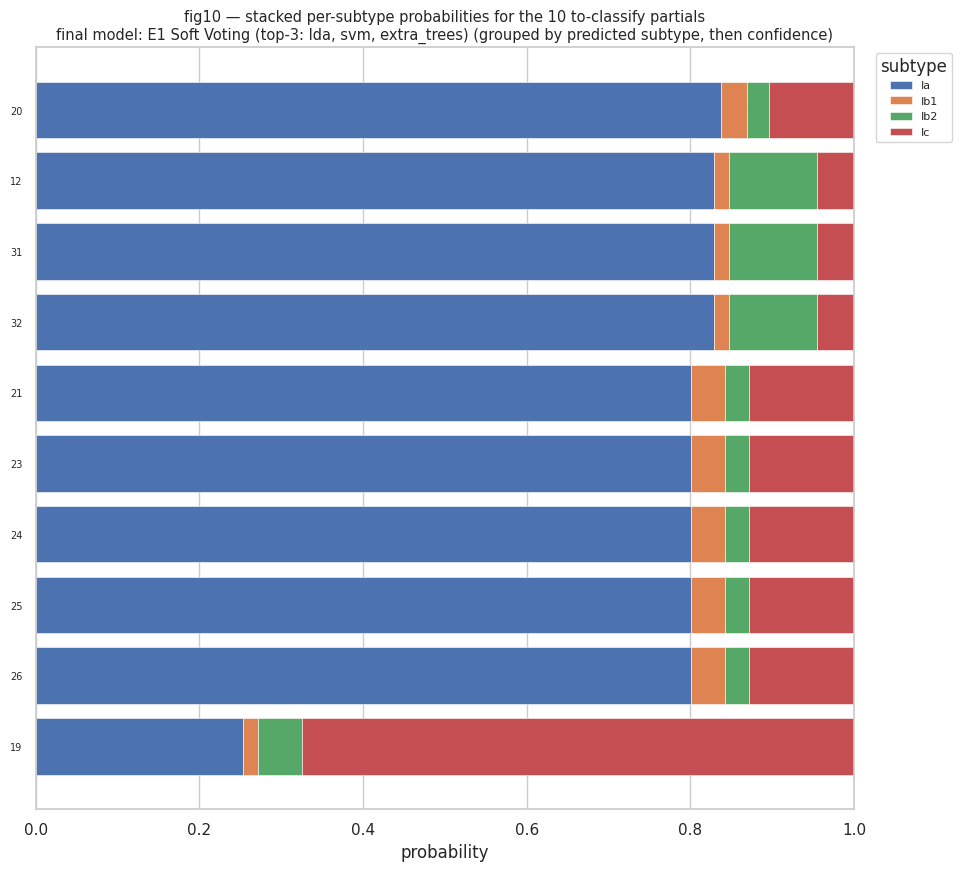

In [34]:
plot_df = PRED_WIDE.copy()
plot_df['seq_id_num'] = plot_df['seq_id'].astype(int)
plot_df['pred_code'] = plot_df['predicted'].map({st: i for i, st in enumerate(CLASSES)})
plot_df = plot_df.sort_values(['pred_code', 'confidence'], ascending=[True, False]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.5, 8.6), constrained_layout=True)
left = np.zeros(len(plot_df))
for st in CLASSES:
    vals = plot_df[f'P_{st}'].values
    ax.barh(range(len(plot_df)), vals, left=left, color=palette[st], edgecolor='white',
            linewidth=0.4, label=st)
    left = left + vals
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df['seq_id'].astype(str), fontsize=7)
ax.invert_yaxis()
ax.set_xlim(0, 1.0)
ax.set_xlabel('probability')
ax.set_title(f'fig10 — stacked per-subtype probabilities for the 10 to-classify partials\nfinal model: {RESULTS[best_key]["name"]} '
             '(grouped by predicted subtype, then confidence)', fontsize=10.5)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8, title='subtype')
save_and_show('fig10_stacked_probabilities.png', fig)

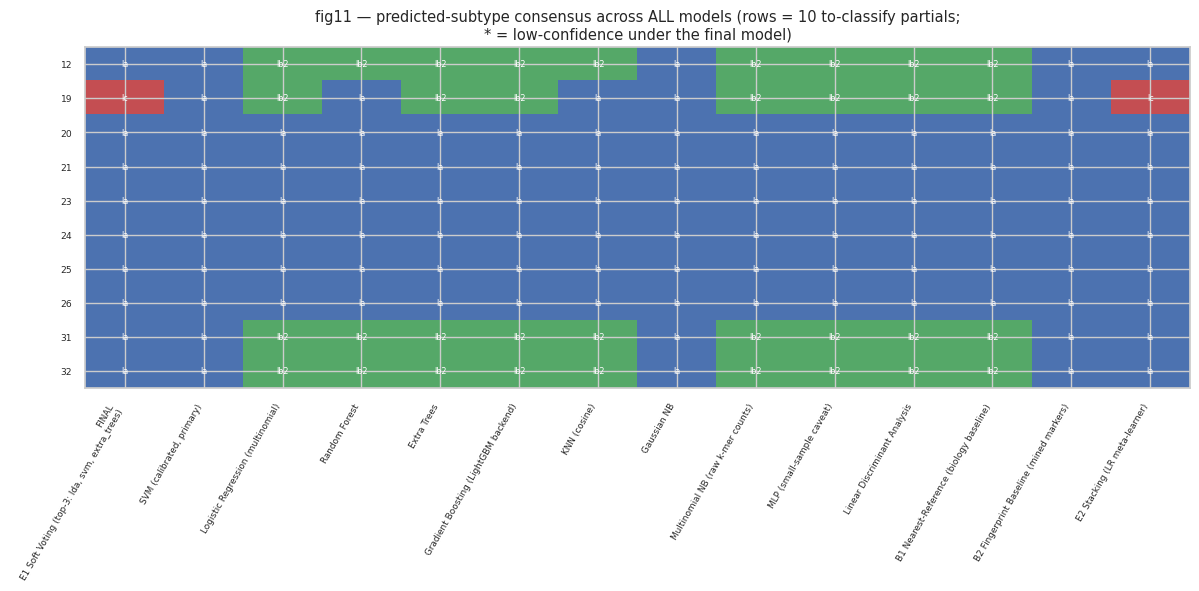

In [35]:
model_order = [best_key] + [k for k in RESULTS.keys() if k != best_key]
cons = np.zeros((len(pred_mat.index), len(model_order)))
for j, mk in enumerate(model_order):
    col = pred_mat[mk]
    for i, sid in enumerate(pred_mat.index):
        cons[i, j] = CLASSES.index(col.loc[sid])
from matplotlib.colors import ListedColormap, BoundaryNorm
cmap4 = ListedColormap([palette[st] for st in CLASSES])
fig, ax = plt.subplots(figsize=(0.62 * len(model_order) + 3.2, 5.8), constrained_layout=True)
ax.imshow(cons, cmap=cmap4, norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap4.N), aspect='auto')
ax.set_xticks(range(len(model_order)))
ax.set_xticklabels(['FINAL\n' + RESULTS[k]['name'] if k == best_key else RESULTS[k]['name'] for k in model_order],
                   rotation=60, ha='right', fontsize=6.4)
ax.set_yticks(range(len(pred_mat.index)))
low_ids = set(PRED_WIDE.loc[PRED_WIDE['low_confidence'], 'seq_id'].astype(str))
ax.set_yticklabels([f'{sid}{" *" if sid in low_ids else ""}' for sid in pred_mat.index], fontsize=6.6)
for i in range(cons.shape[0]):
    for j in range(cons.shape[1]):
        ax.text(j, i, CLASSES[int(cons[i, j])], ha='center', va='center', fontsize=5.8,
                color='white')
ax.set_title('fig11 — predicted-subtype consensus across ALL models (rows = 10 to-classify partials;\n'
             '* = low-confidence under the final model)', fontsize=10.5)
save_and_show('fig11_consensus_heatmap.png', fig)

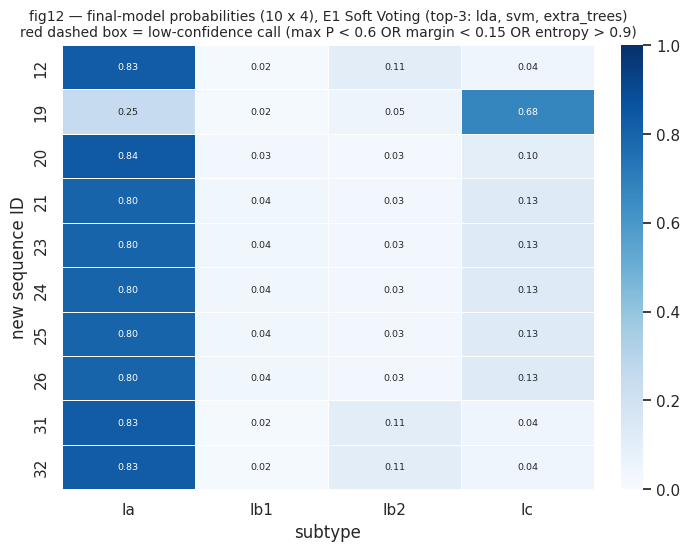

In [36]:
pmat = PRED_WIDE.set_index('seq_id')[[f'P_{st}' for st in CLASSES]].astype(float)
pmat = pmat.sort_index(key=lambda idx: idx.astype(int))
fig, ax = plt.subplots(figsize=(6.8, 5.4), constrained_layout=True)
if HAS_SNS:
    sns.heatmap(pmat.values, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=True,
                xticklabels=CLASSES, yticklabels=pmat.index, ax=ax, annot_kws={'fontsize': 6.8},
                linewidths=0.4, linecolor='white')
else:
    ax.imshow(pmat.values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(4)); ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(len(pmat))); ax.set_yticklabels(pmat.index, fontsize=6.6)
    for i in range(pmat.shape[0]):
        for j in range(pmat.shape[1]):
            ax.text(j, i, f'{pmat.values[i, j]:.2f}', ha='center', va='center', fontsize=6.5)
for i, sid in enumerate(pmat.index):
    if str(sid) in low_ids:
        ax.add_patch(plt.Rectangle((0 - 0.0, i - 0.5), 4, 1, fill=False, edgecolor='red',
                                   ls='--', lw=1.4))
ax.set_title(f'fig12 — final-model probabilities (10 x 4), {RESULTS[best_key]["name"]}\n'
             'red dashed box = low-confidence call (max P < 0.6 OR margin < 0.15 OR entropy > 0.9)', fontsize=10)
ax.set_xlabel('subtype'); ax.set_ylabel('new sequence ID')
save_and_show('fig12_probability_heatmap.png', fig)

## Limitations & Practical Recommendation

**Limitations of this analysis.**

1. **Mined-marker assumptions.** Digital fingerprints are only as good as the reference panel: a subtype with no strictly diagnostic k-mer at any tested (k, X, Y) threshold simply cannot be fingerprinted by this method (its identity is carried by allele *combinations* and, in this corpus, by sequence-identical rows carrying conflicting labels), and markers mined from a ~40-row combined corpus — where the rarest subtypes rest on only 2-8 unique genomes — may not transfer to newly circulating lineages.
2. **Partial-genome composition bias.** All evidence comes from one ~250-nt amplicon. Fingerprint "totals" in the CSV plausibly count genome-wide identifiers of which this fragment samples only a subset — a systematic reason why mined profiles under-reproduce CSV scores (fragment-coverage effect, not necessarily mislabeling).
3. **Oversampling adds no biology.** The "pick the highest value" balancing duplicates existing minority-row sequences with replacement; it equalizes effective training counts and stabilizes majority-vote behaviour, but it cannot create new diversity. The fold-safe implementation keeps CV metrics honest (copies never enter validation folds), yet duplicated rows can still make minority-subtype probabilities optimistically confident, and rare-subtype knowledge remains bounded by its few unique genomes.
4. **Reference coverage.** Even after integrating the 22 user-labeled partials, the corpus holds only ~40 original rows; CV metrics carry wide uncertainty and the 80/20 hold-out rests on ~8 rows — CV/OOF numbers are the primary evidence, held-out numbers are protocol compliance.
5. **Calibration at this scale.** Sigmoid calibration with adaptive inner folds on a few dozen rows yields coarse reliability; fig8 indicates direction of miscalibration, not a precise curve. Probabilities for the 10 targets should be read as *ranked confidence*, not true posterior frequencies.
6. **Schema-B self-score unusable at inference.** The single self-score is label-dependent and therefore cannot be computed for new sequences; only its mined-marker *proxy* (validated, and here found insufficient) is available — a permanent information gap of Schema B vs Schema A.
7. **User labels are taken as ground truth.** The 22 user-provided labels were integrated verbatim into the training corpus and into the balancing; if any of them is wrong, it propagates into every model. The Step-8b LOOCV consistency check quantifies (but cannot remove) this risk, and the label-noise sensitivity analysis prices the flagged-reference component of it.
8. **Near-duplicates.** Several partials are >99% k-mer-identical to corpus rows (disclosed in Step 1f); their predictions are near-interpolations and optimistically confident. One reference sequence appears under two different subtype labels — the strongest single caveat in this corpus.

**Practical recommendation for future sequences.** (i) Type new samples by running them through the *frozen* winner pipeline (re-fitted on all training data, fold-safe balance-augmented) and report the probability vector + confidence/margin/entropy plus the mined fingerprint profile; (ii) route every low-confidence, cross-model-disagreement or LOOCV-mismatched call to lab confirmation with a longer amplicon; (iii) grow the reference panel per subtype — especially the rarest subtypes whose balanced training counts are copies of very few unique genomes — and re-mine markers with the same pre-registered sweep; (iv) if possible, move the corpus to **SCHEMA A** (per-subtype fingerprint profiles), which enables true fingerprint features and a properly validated hybrid model at inference time; (v) resolve the sequence-identical conflicting-label rows by sequencing arbitration before the next training round; (vi) extend user-labeling to the 10 remaining partials only after laboratory confirmation, then re-run this notebook unchanged.
